# MSc AI - University of Essex & Aegean College

**Module Title:** Deep Learning & Neural Nets<br>
**Module Code:** AI105<br>
**Submission Date:** 23/11/2026

## Student Details:
**Name:** Tsagaridis Alexandros (Αλέξανδρος Τσαγγαρίδης)<br>
**Student ID:** 130-11619<br>

## Assessment Title

You are working as a data scientist in a telecommunications company that faces increasing customer churn, i.e., the percentage of customers leaving the service for competitors. Your task is to design, implement, and evaluate a neural network model using Python and TensorFlow to predict customer churn, and compare it against a simpler baseline model (e.g., Logistic Regression).

The company wants actionable insights – not only predictive accuracy but also an understanding of which customer segments are at risk and how predictive modelling can be used strategically. You will use the Telco Customer Churn dataset (available on Kaggle or UCI).

### **Part 1** - Dataset Exploration and Preprocessing

In [1]:
#Libaries Cell
#We will keep importing new libraries depending the assignment needs.

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

In [ ]:
#A1. Describe the dataset (features, target variable, distributions).

df = pd.read_csv("assignment.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


21 features in the dataset. Target feature "Yes/No" classification. "Churn" feature is the target/label.
Lets try bit deeper. Shape and features.

In [3]:
#Shape
print("Dataset shape:", df.shape)

#Feature Name
print("\nDataset columns:")
for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

Dataset shape: (7043, 21)

Dataset columns:
1. customerID
2. gender
3. SeniorCitizen
4. Partner
5. Dependents
6. tenure
7. PhoneService
8. MultipleLines
9. InternetService
10. OnlineSecurity
11. OnlineBackup
12. DeviceProtection
13. TechSupport
14. StreamingTV
15. StreamingMovies
16. Contract
17. PaperlessBilling
18. PaymentMethod
19. MonthlyCharges
20. TotalCharges
21. Churn


In [4]:
#Target Variable, count and % of each class(Yes/No, Stayed/Left)

target="Churn"

print ("Distribution:")
print(df[target].value_counts())
print("-"*50)
print("Churn %:")
print(df[target].value_counts(normalize=True)*100)
print("-"*50)
print("Rounded %:")
print((df[target].value_counts(normalize=True) * 100).round(2))

Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
--------------------------------------------------
Churn %:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64
--------------------------------------------------
Rounded %:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [5]:
# Data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
#TotalCharges variable shows as "str". We examine this later.
#Numerical values: tenure, MonthlyCharges (Χρόνος Παραμονης και Χρέωση/μήνα)

#Select the features
numeric_features = ["tenure", "MonthlyCharges"]
print("Statistics:")
print("-"*50)
print(df[numeric_features].describe().round(2))

Statistics:
--------------------------------------------------
        tenure  MonthlyCharges
count  7043.00         7043.00
mean     32.37           64.76
std      24.56           30.09
min       0.00           18.25
25%       9.00           35.50
50%      29.00           70.35
75%      55.00           89.85
max      72.00          118.75


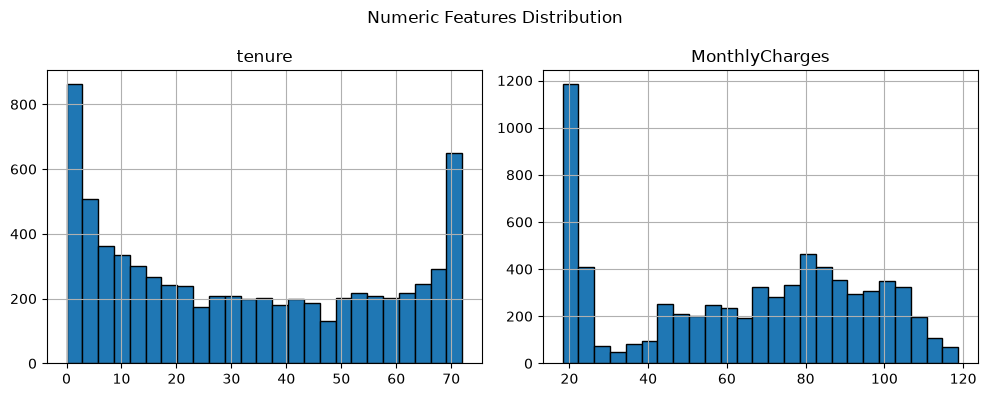

In [7]:
#Distribution of each feature in histogram

df[numeric_features].hist(
    bins=25,
    figsize=(10,4),
    edgecolor="black"
)
plt.suptitle("Numeric Features Distribution")
plt.tight_layout()
plt.show()

In [8]:
#Categorical features.
#Το "Tech Support" πάντα είναι ένα από τα σημαντικότερα, όταν αυτο βέβαια μπορεί να επιβεβαιώση το "satisfaction" κάθε πελάτη. 

print("Lets Check TechSupport Closer!")
print("="*40)
print(df["TechSupport"].value_counts())
print("\nPercentages:")
print((df["TechSupport"].value_counts(normalize=True)*100).round(2))

Lets Check TechSupport Closer!
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

Percentages:
TechSupport
No                     49.31
Yes                    29.02
No internet service    21.67
Name: proportion, dtype: float64


In [9]:
#Άρα έχουμε 3 κατηγορίες."Yes/No/No internet service".

print(pd.crosstab(df["TechSupport"], df["Churn"]))

Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310


In [10]:
#Μοιάζει να υπάρχει κάτι. Μόλις "310" στο churn=Yes όταν υπάρχει support.
#Για να βγεί καί σε %
print(
    (pd.crosstab(
        df["TechSupport"],
        df["Churn"],
        normalize="index"
    ) * 100).round(2))

Churn                   No    Yes
TechSupport                      
No                   58.36  41.64
No internet service  92.60   7.40
Yes                  84.83  15.17


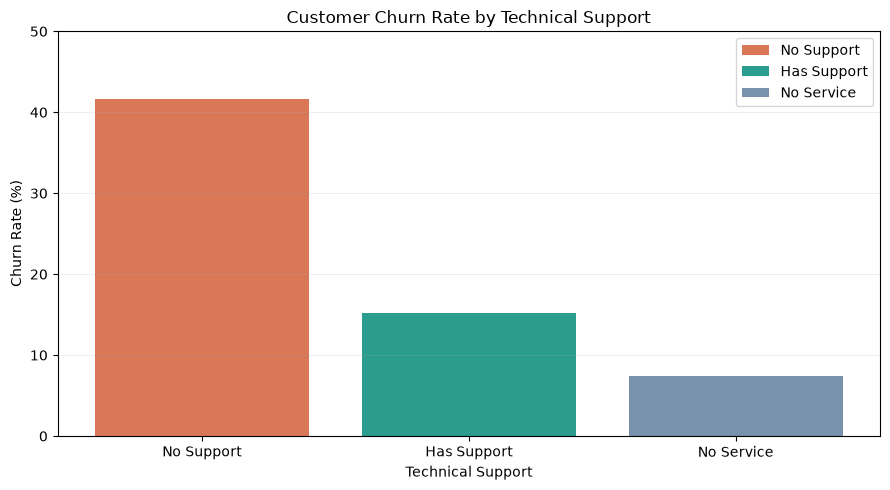

In [11]:
#Μόνο 15% στο Yes service. Ενα barchart θα ήταν καλό για το report.
#Churns
churn_rates = (pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index")["Yes"] * 100)

churn_rates = churn_rates.reindex([
    "No","Yes","No internet service"
])

#Make the plot
plt.figure(figsize=(9,5))
bars= plt.bar(["No Support", "Has Support", "No Service"],
              churn_rates,
              color=["#D97757", "#2A9D8F", "#7891AD"])
for bar, label in zip(bars, ["No Support", "Has Support", "No Service"]):
    bar.set_label(label)
plt.legend(loc="upper right")
plt.title("Customer Churn Rate by Technical Support")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Technical Support")
plt.ylim(0, 50)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [12]:
# Select features. Churn and CustomerId excluded.

categorical_features = [
   "gender",
   "SeniorCitizen",
   "Partner",
   "Dependents",
   "PhoneService",
   "MultipleLines",
   "InternetService",
   "OnlineSecurity",
   "OnlineBackup",
   "DeviceProtection",
   "TechSupport",
   "StreamingTV",
   "StreamingMovies",
   "Contract",
   "PaperlessBilling",
   "PaymentMethod"
]

# Display counts and percentages for each category
for feature in categorical_features:

    print(f"\n{feature} Distribution:")
    print("-" * 50)

    counts = df[feature].value_counts()
    percentages = (
        df[feature].value_counts(normalize=True) * 100).round(2)

    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage (%)": percentages
    })

    print(distribution)


gender Distribution:
--------------------------------------------------
        Count  Percentage (%)
gender                       
Male     3555           50.48
Female   3488           49.52

SeniorCitizen Distribution:
--------------------------------------------------
               Count  Percentage (%)
SeniorCitizen                       
0               5901           83.79
1               1142           16.21

Partner Distribution:
--------------------------------------------------
         Count  Percentage (%)
Partner                       
No        3641            51.7
Yes       3402            48.3

Dependents Distribution:
--------------------------------------------------
            Count  Percentage (%)
Dependents                       
No           4933           70.04
Yes          2110           29.96

PhoneService Distribution:
--------------------------------------------------
              Count  Percentage (%)
PhoneService                       
Yes            63

In [13]:
#We pick to examine for each churn: "contract type, internet service, and payment method".
features = ["Contract", "InternetService", "PaymentMethod"]

for feature in features:

    counts = pd.crosstab(df[feature], df["Churn"])

    churn_rate = (counts["Yes"] / counts.sum(axis=1) * 100).round(2)

    results = counts.copy()
    results["Churn Rate (%)"] = churn_rate
    results = results.sort_values(
        by="Churn Rate (%)", ascending=False)

    print(f"\n{feature} vs Churn:")
    print("-" * 50)
    print(results)


Contract vs Churn:
--------------------------------------------------
Churn             No   Yes  Churn Rate (%)
Contract                                  
Month-to-month  2220  1655           42.71
One year        1307   166           11.27
Two year        1647    48            2.83

InternetService vs Churn:
--------------------------------------------------
Churn              No   Yes  Churn Rate (%)
InternetService                            
Fiber optic      1799  1297           41.89
DSL              1962   459           18.96
No               1413   113            7.40

PaymentMethod vs Churn:
--------------------------------------------------
Churn                        No   Yes  Churn Rate (%)
PaymentMethod                                        
Electronic check           1294  1071           45.29
Mailed check               1304   308           19.11
Bank transfer (automatic)  1286   258           16.71
Credit card (automatic)    1290   232           15.24


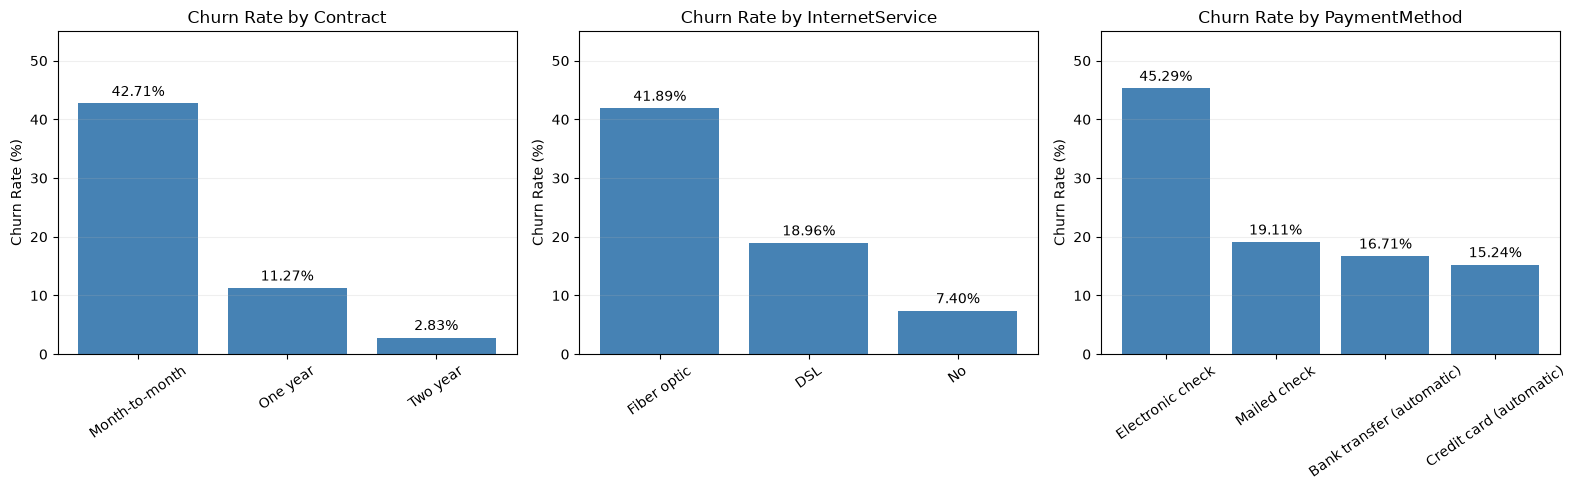

In [14]:
#Visualize the tables above
features = ["Contract", "InternetService", "PaymentMethod"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, features):

    churn_rate = (
        pd.crosstab(df[feature], df["Churn"],
                    normalize="index")["Yes"] * 100).sort_values(ascending=False)

    bars = ax.bar(
        churn_rate.index,
        churn_rate.values,
        color="#4682B4")

    ax.bar_label(bars, fmt="%.2f%%", padding=3)
    ax.set_title(f"Churn Rate by {feature}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [14]:
#A2. PERFORM DATA CLEANING AND PREPROCESSING

#Missing Values
print("Missing Values:")
print(df.isna().sum())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [15]:
#Blank or whitespaces in "TotalCharges" feature
blank_values = df["TotalCharges"].str.strip().eq("").sum()
print("Blank TotalCharges:", blank_values)

Blank TotalCharges: 11


In [16]:
#Attempt to numeric convarsion of "TotalCharges"
numeric_charges = pd.to_numeric(
    df["TotalCharges"], errors="coerce")
print("Non-Numeric:", numeric_charges.isna().sum())
print("-"*50)

#Connect invalid TotalCharges values to customer record
print("Invalid Values:")
print(df.loc[numeric_charges.isna(),
             ["tenure","TotalCharges","Churn"]])

Non-Numeric: 11
--------------------------------------------------
Invalid Values:
      tenure TotalCharges Churn
488        0                 No
753        0                 No
936        0                 No
1082       0                 No
1340       0                 No
3331       0                 No
3826       0                 No
4380       0                 No
5218       0                 No
6670       0                 No
6754       0                 No


Έχουμε λοιπόν τελικά 11 missing values. Αν δουμε καλύτερα, αυτά τα client records έχουνε και tenure 0. Το πιθανότερο είναι νέοι πελάτες μια και έχουν 0 συνδρομές. Μπορούμε είτε να τις μηδενίσουμε είτε να τις διαγράωουμε. Αποτελούν μόλις το 0.16% του original dataset και καλύτερα να διαγραφούν παρά αργότερα ένα ουσιαστικά null value να μετατραπεί σε αριθμητικό μηδέν.

In [17]:
#Delete the NaNs
#Better make new dataset
df_clean = df.copy()

#Convert to numeric
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce")

#Remove the records
df_clean = df_clean.dropna(
    subset=["TotalCharges"]).copy()

In [18]:
#Verify results
print("Original shape:", df.shape)
print("New shape:", df_clean.shape)
print("-"*50)
print("Records Removed:", len(df) - len(df_clean))
print("-"*50)
print("Data Type:", df_clean["TotalCharges"].dtype)
print("-"*50)
print("Remaining NaNs:", df_clean.isna().sum())

Original shape: (7043, 21)
New shape: (7032, 21)
--------------------------------------------------
Records Removed: 11
--------------------------------------------------
Data Type: float64
--------------------------------------------------
Remaining NaNs: customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [19]:
#Quick check for duplicates IDs and rows
print("Duplicate Customer IDs:",
      df_clean["customerID"].duplicated().sum())
print("Duplicate Rows:",
      df_clean.duplicated().sum())

Duplicate Customer IDs: 0
Duplicate Rows: 0


Αποφασίστηκε ότι καλύτερα να γίνει split σε 65/15/20, train/validate/test. Το split στο df_clean, τελικό dataset, καλύτερα να γίνει απο τώρα για όλα τα subsets για αποφυγή τυχών data leakage. Αφού πρώτα αφαιρεθεί το 20% του dataset (df_clean), θα παραμείνει το 80% για να αφαιρεθεί το 15% για validation. Άρα το 15/80 θα είναι το 18.75% του 80% που απέμεινε.<br>
To "customerId" και το "Churn" θα αφαιρεθούν σαν feature data,μια και το ένα είναι στην ουσία το output (churn).

In [20]:
#Lets make the split seperation
#Create X,y data and Churn to numerical
X = df_clean.drop(columns=["customerID","Churn"])
y = df_clean["Churn"].map({"No":0,"Yes":1})

#Test data split, remaining train and validation sets
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

#Split the validation set also. It is 18.75% of the original 100%.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.1875,
    random_state=42,
    stratify=y_train_val
)

#Datasets shapes
print("Training Set:", X_train.shape, y_train.shape)
print("Validation Set:", X_val.shape, y_val.shape)
print("Test Set:", X_test.shape, y_test.shape)

Training Set: (4570, 19) (4570,)
Validation Set: (1055, 19) (1055,)
Test Set: (1407, 19) (1407,)


In [21]:
#Categorical to Numerical convertion. We will use one-hot encoding. For example at contract month= 100, 1year=010 and 2years=001.
#Same for TechSupport, paymentMethod etc etc

#From training set identify the categorical features
categorical_cols = X_train.select_dtypes(
    include=["object", "str", "category"]).columns.tolist()
print("Categorical Features:", len(categorical_cols))

#One-hot encoding
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False)

#Fit only on training data
encoder.fit(X_train[categorical_cols])

#Re-usable function for each dataset
def encode_data(X):
    encoded=pd.DataFrame(
        encoder.transform(X[categorical_cols]),
        columns=encoder.get_feature_names_out(categorical_cols),
        index=X.index)
    numeric=X.drop(columns=categorical_cols)
    return pd.concat([numeric, encoded], axis=1)

#Apply the encoder to all sets
X_train_encoded = encode_data(X_train)
X_val_encoded = encode_data(X_val)
X_test_encoded = encode_data(X_test)

Categorical Features: 15


In [22]:
#Verify encoding results
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)
print("="*40)
print("Remaining Categorical Columns:", len(X_train_encoded.select_dtypes(
    include=["object", "str", "category"]).columns))

Training: (4570, 45)
Validation: (1055, 45)
Testing: (1407, 45)
Remaining Categorical Columns: 0


Encoding complete!<br>
Τώρα μπορούμε να πρωχωρήσουμε στο standarization. Θα γίνει με standardscaler στα features: tenure, MonthlyCharges, TotalCharges. Το SeniorCitizen και όλα τα one-hot encoded features θα παραμείνουν 0/1.

In [23]:
#Select features and create the scaler
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

#Set the new Datasets
X_train_std = X_train_encoded.copy()
X_val_std = X_val_encoded.copy()
X_test_std = X_test_encoded.copy()

#Fit only on training and transform all sets
X_train_std[numeric_cols] = scaler.fit_transform(
    X_train_encoded[numeric_cols])
X_val_std[numeric_cols] = scaler.transform(
    X_val_encoded[numeric_cols])
X_test_std[numeric_cols] = scaler.transform(
    X_test_encoded[numeric_cols])

In [24]:
#Visual and verify results of standarization.
print("Statistics:")
print("-"*50)
print(X_train_std[numeric_cols].agg(["mean","std"]).round(3))
print("-"*50)
print("Training Dims:", X_train_std.shape)
print("Validation Dims:", X_val_std.shape)
print("Testing Dims:", X_test_std.shape)

#Missing Values (If any) after scaler
print("Remaining NaNs:",
      X_train_std.isna().sum().sum(),
      X_val_std.isna().sum().sum(),
      X_test_std.isna().sum().sum())

Statistics:
--------------------------------------------------
      tenure  MonthlyCharges  TotalCharges
mean     0.0            -0.0          -0.0
std      1.0             1.0           1.0
--------------------------------------------------
Training Dims: (4570, 45)
Validation Dims: (1055, 45)
Testing Dims: (1407, 45)
Remaining NaNs: 0 0 0


### **PART 2** - Logistic Regression Model

Τα δεδομένα είναι πλέον έτοιμα για εκπαίδευση στο μοντέλο. Το 1ο πείραμα θα γίνει με Logistic Regression Model. Θα χρειαστεί να κάνουμε import και το LogisticRegression από sklearn library. Ένα καινούργιο cell για τα libraries που θα χρειαστούν πιο κάτω

In [25]:
#Importing new libraries

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

In [27]:
#Build and train the baseline model

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42)
lr_model.fit(X_train_std, y_train)

#Verify
print("Model:", lr_model)
print("Features:", lr_model.n_features_in_)
print("Classes:", lr_model.classes_)

Model: LogisticRegression(max_iter=1000, random_state=42)
Features: 45
Classes: [0 1]


In [28]:
#Predict and %
y_val_pred = lr_model.predict(X_val_std)
y_val_prob = lr_model.predict_proba(X_val_std)[:,1]

In [29]:
#Metrics
print("Logistic Regression Metrics - Validation Data")
print("-"*50)
print("Accuracy:", round(accuracy_score(y_val,y_val_pred),4))
print("Precision:", round(precision_score(y_val, y_val_pred),4))
print("Recall:", round(recall_score(y_val, y_val_pred),4))
print("F1 Score:", round(f1_score(y_val,y_val_pred),4))
print("ROC-AUC(%):", round(roc_auc_score(y_val,y_val_prob),4)*100)

Logistic Regression Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7858
Precision: 0.6144
Recall: 0.5179
F1 Score: 0.562
ROC-AUC(%): 83.69


Acc 78.58% σε ένα dataset πού αρχικά έχει 73.46% churn "NO" (stayed).<br>
Το Reacall όμως που σε μία τέτοια εταιρία είναι πολύ σημαντικό είναι μόλις 51.79%.

In [30]:
#Confussion Matrix
cm = confusion_matrix(y_val, y_val_pred)
print("Logististic Regression Matrix")
print("-"*50)
print(cm)

#TP, FP, TN, FN
tn,fp,fn,tp = cm.ravel()
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Logististic Regression Matrix
--------------------------------------------------
[[684  91]
 [135 145]]
True Negatives: 684
False Positives: 91
False Negatives: 135
True Positives: 145


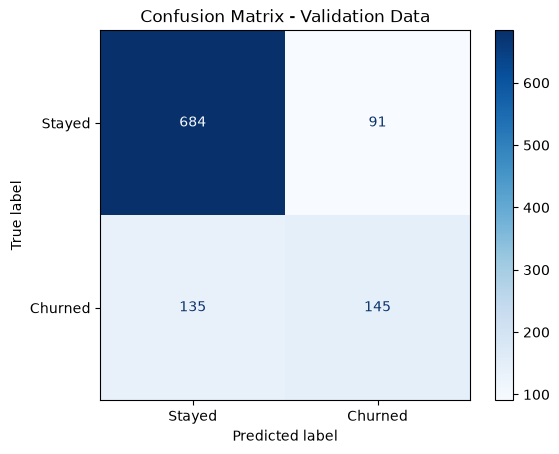

In [31]:
#Plot the Matrix
ConfusionMatrixDisplay.from_predictions(y_val,y_val_pred,
                                        display_labels=["Stayed", "Churned"],
                                        cmap="Blues",
                                        values_format="d")
plt.title("Confusion Matrix - Validation Data")
plt.show()

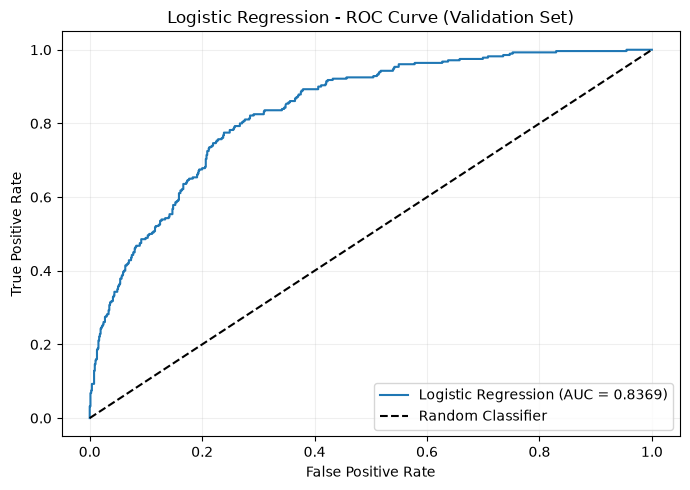

In [32]:
#ROC curve plot

#Using validation probabilities
fpr, tpr, thresholds = roc_curve(y_val,y_val_prob)

#AUC
roc_auc = auc(fpr,tpr)

#plot
plt.figure(figsize=(7,5))
plt.plot(fpr,tpr,label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0,1],[0,1],"k--",label="Random Classifier")
plt.title("Logistic Regression - ROC Curve (Validation Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [33]:
#Save Logistic Regression model

import joblib

joblib.dump(lr_model, "logistic_regression.joblib")

['logistic_regression.joblib']

### **PART 3** - Neural Nets

Θα ξεκινήσουμε με ένα απλό σχετικά νευρωνικό. 45 inputs όπως τα features. 2 hidden layers of 32 and 16 nodes each. Activation = relu for non-linear relationships.<br>
Output is sigmoid with 1 node for probability result. Binary churn classification output.<br>
Adam for optimizing and binary crossentropy as loss function during training.<br>

In [26]:
#Libraries

import tensorflow as tf

In [27]:
#Set seeds

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

In [ ]:
#Build initial MLP

mlp_basic = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_std.shape[1],)),
    tf.keras.layers.Dense(32, activation = "relu"),
    tf.keras.layers.Dense(16, activation = "relu"),
    tf.keras.layers.Dense(1, activation = "sigmoid")],
    name = "MLP_Basic")

In [54]:
#Compile basic model

mlp_basic.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001),
    loss = "binary_crossentropy",
    metrics = [tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
               tf.keras.metrics.AUC(name="AUC")]
)

In [55]:
#Summaries

mlp_basic.summary()

Model: "MLP_Basic"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
#Train the model using history. Early stop used for 10 epochs no improvement.

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 10,
    restore_best_weights=True
)

history_basic = mlp_basic.fit(
    X_train_std.to_numpy(dtype="float32"),
    y_train.to_numpy(dtype="float32"),
    validation_data = (
        X_val_std.to_numpy(dtype="float32"),
        y_val.to_numpy(dtype="float32")),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.7773 - Accuracy: 0.7663 - loss: 0.4813 - val_AUC: 0.8232 - val_Accuracy: 0.7877 - val_loss: 0.4407
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8430 - Accuracy: 0.8004 - loss: 0.4204 - val_AUC: 0.8335 - val_Accuracy: 0.7915 - val_loss: 0.4306
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8496 - Accuracy: 0.8059 - loss: 0.4126 - val_AUC: 0.8344 - val_Accuracy: 0.7953 - val_loss: 0.4293
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8527 - Accuracy: 0.8085 - loss: 0.4086 - val_AUC: 0.8338 - val_Accuracy: 0.7905 - val_loss: 0.4294
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8550 - Accuracy: 0.8112 - loss: 0.4059 - val_AUC: 0.8339 - val_Accuracy: 0.7915 - val_loss: 0.4297
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8568 - Accuracy: 0.8138 - loss: 0.4037 - val_AUC: 0.8338 - val_Accuracy: 0.7934 - val_loss: 0.4296
Epoch 7/100
143/143 ━━━━━━━━━━━━━━

To traing τελείωσε στο epoch 13. Αυτό έγινε γιατί το early stop patience ήταν 10. Έτσι παρόλο που τα καλύτερα αποτελέσματα ήτανε στο epoch 3 το early stop λειτούργησε στο epoch 13. Όμως με restore best weights = TRUE το μοντέλο κράτησε τα weights του epoch 3.

In [57]:
#Save the model and training history

mlp_basic.save("mlp_basic.keras")

pd.DataFrame(history_basic.history).to_csv(
    "mlp_basic_history.csv",
    index=False
)

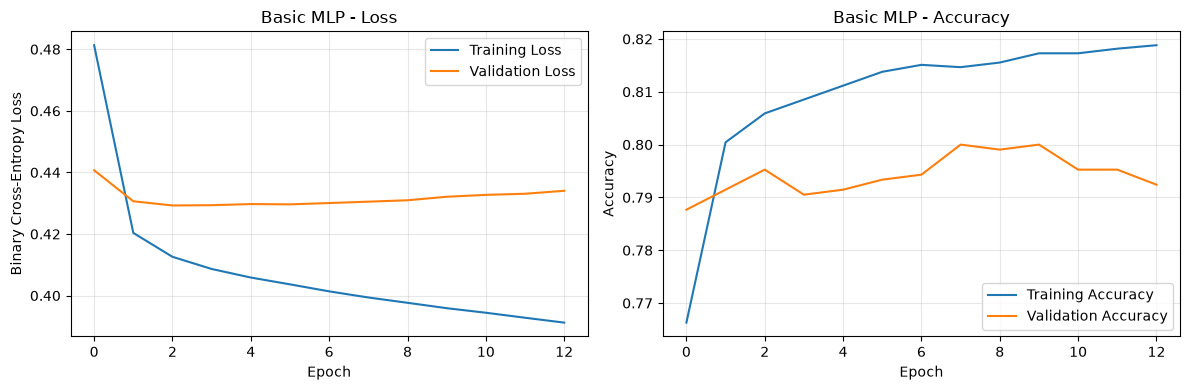

In [58]:
# Plot training and validation loss/accuracy

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(history_basic.history["loss"], label="Training Loss")
axes[0].plot(history_basic.history["val_loss"], label="Validation Loss")
axes[0].set_title("Basic MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(history_basic.history["Accuracy"], label="Training Accuracy")
axes[1].plot(history_basic.history["val_Accuracy"], label="Validation Accuracy")
axes[1].set_title("Basic MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
#Evaluate the model

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

#Churn probabilities
y_val_prob_mlp = mlp_basic.predict(
    X_val_std.to_numpy(dtype="float32"),
    verbose=0
).ravel()

# Probabilities to binary predictions
y_val_pred_mlp = (y_val_prob_mlp >= 0.5).astype(int)

# Validation metrics
print("Basic MLP Metrics - Validation Data")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_mlp), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_mlp), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_mlp), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_mlp), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_mlp), 4))
print("-" * 50)
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_mlp))


Basic MLP Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7953
Precision: 0.6322
Recall: 0.5464
F1 Score: 0.5862
ROC-AUC: 0.8343
--------------------------------------------------
Confusion Matrix:
[[686  89]
 [127 153]]


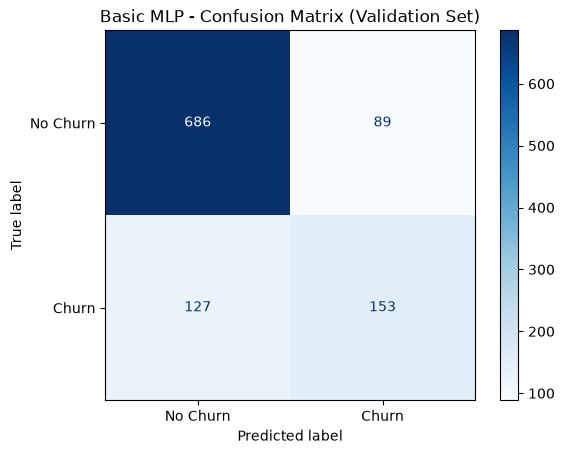

In [ ]:
#Confusion Matrix (Validation Set)

cm_mlp = confusion_matrix(y_val, y_val_pred_mlp)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_mlp,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Basic MLP - Confusion Matrix (Validation Set)")
plt.show()

In [61]:
# Compare Logistic Regression and Basic MLP on validation data

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Basic MLP"],
    "Accuracy": [0.7858, 0.7953],
    "Precision": [0.6144, 0.6322],
    "Recall": [0.5179, 0.5464],
    "F1 Score": [0.5620, 0.5862],
    "ROC-AUC": [0.8369, 0.8343]
})

display(comparison)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343


In [62]:
#Checking kernel after long time in idle

print(mlp_basic.name)
print(X_train_std.shape)
print(X_val_std.shape)

MLP_Basic
(4570, 45)
(1055, 45)


Το μοντέλο είναι ελαφρώς καλύτερο από το regression. Μοιάζει όμως να μη γενικεύει καλά και πάσχει από overfitting. Θα ξαναδοκιμάσουμε με “batch normalizition” μήπως και πετύχουμε καλύτερη γενίκευση (μικρότερο validation loss).<br>
Το νέο μοντέλο τώρα είναι mlp_bn.

In [63]:
#Build the new model. mlp_bn

tf.keras.utils.set_random_seed(42)

mlp_bn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_std.shape[1],)),
    tf.keras.layers.Dense(32),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dense(16),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")], 
    name="MLP_BatchNorm")

In [64]:
#Summary

mlp_bn.summary()

Model: "MLP_BatchNorm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209 (8.63 KB)

 Trainable params: 2,113 (8.25 KB)

 Non-trainable params: 96 (384.00 B)

**NOTE**: 192 additional parameters compared with the Basic MLP.<br>
Compile again exactly like basic model.

In [65]:
#Compile new model

mlp_bn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
        tf.keras.metrics.AUC(name="AUC")
    ]
)

In [66]:
#Re-train model with same number of epochs like the basic and same callbacks

early_stop_bn = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True)

history_bn = mlp_bn.fit(
    X_train_std.to_numpy(dtype="float32"),
    y_train.to_numpy(dtype="float32"),
    validation_data=(
        X_val_std.to_numpy(dtype="float32"),
        y_val.to_numpy(dtype="float32")),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop_bn],
    verbose=1)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - AUC: 0.7836 - Accuracy: 0.7580 - loss: 0.4890 - val_AUC: 0.8118 - val_Accuracy: 0.7829 - val_loss: 0.4754
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.8371 - Accuracy: 0.7969 - loss: 0.4272 - val_AUC: 0.8239 - val_Accuracy: 0.7810 - val_loss: 0.4428
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8475 - Accuracy: 0.8042 - loss: 0.4148 - val_AUC: 0.8264 - val_Accuracy: 0.7848 - val_loss: 0.4382
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - AUC: 0.8533 - Accuracy: 0.8063 - loss: 0.4081 - val_AUC: 0.8267 - val_Accuracy: 0.7848 - val_loss: 0.4374
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8578 - Accuracy: 0.8114 - loss: 0.4027 - val_AUC: 0.8271 - val_Accuracy: 0.7924 - val_loss: 0.4380
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8617 - Accuracy: 0.8123 - loss: 0.3979 - val_AUC: 0.8258 - val_Accuracy: 0.7886 - val_loss: 0.4387
Epoch 7/100
143/143 ━━━━━━━━━━━━━

In [68]:
#Save model and metrics for later compare with other models

mlp_bn.save("mlp_bn.keras")

pd.DataFrame(history_bn.history).to_csv("mlp_bn_history.csv", index=False)

In [70]:
#Evaluate the BN model on validation data

y_val_prob_bn = mlp_bn.predict(
    X_val_std.to_numpy(dtype="float32"),verbose=0).ravel()

#Probabilities to binary predictions
y_val_pred_bn = (y_val_prob_bn >= 0.5).astype(int)

#Metrics
print("Batch Norm. MLP Metrics - Validation Data")
print("-"*50)
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_bn), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_bn), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_bn), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_bn), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_bn), 4))
print("-" * 50)
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_bn))

Batch Norm. MLP Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7848
Precision: 0.6167
Recall: 0.5
F1 Score: 0.5523
ROC-AUC: 0.8268
--------------------------------------------------
Confusion Matrix:
[[688  87]
 [140 140]]


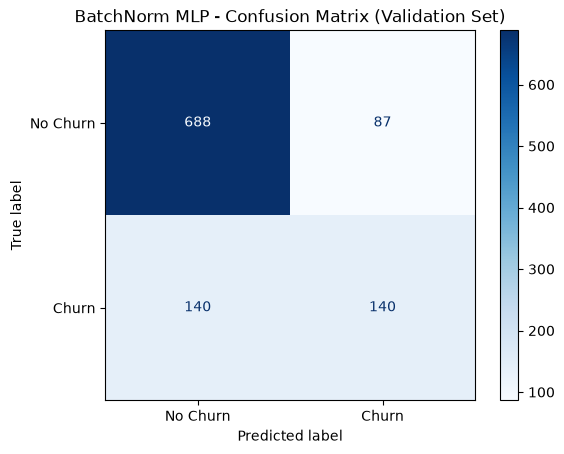

In [72]:

#Confusion Matrix (Validation Set)

cm_bn = confusion_matrix(y_val, y_val_pred_bn)

disp_bn = ConfusionMatrixDisplay(
    confusion_matrix=cm_bn,
    display_labels=["No Churn", "Churn"]
)

disp_bn.plot(cmap="Blues", values_format="d")

plt.title("BatchNorm MLP - Confusion Matrix (Validation Set)")
plt.show()


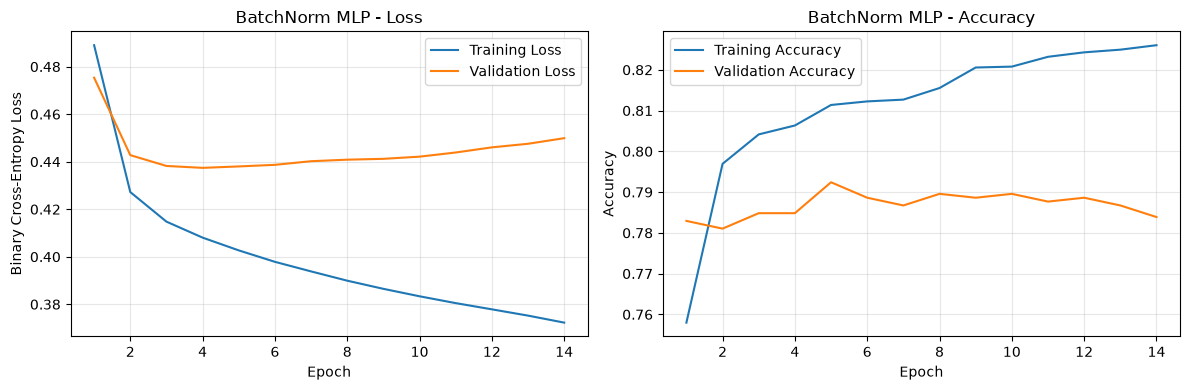

In [73]:
#Training History, with epochs visual as 1 to 13 this time and not 0 to 12, for better visuals
epochs_bn = range(1, len(history_bn.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Loss
axes[0].plot(epochs_bn, history_bn.history["loss"],
             label="Training Loss")
axes[0].plot(epochs_bn, history_bn.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("BatchNorm MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Accuracy
axes[1].plot(epochs_bn, history_bn.history["Accuracy"],
             label="Training Accuracy")
axes[1].plot(epochs_bn, history_bn.history["val_Accuracy"],
             label="Validation Accuracy")
axes[1].set_title("BatchNorm MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Batch Normalization didnt help much. Basically made things bit worse (validation loss).<br>
Before Dropout we can make quick comparisson table of the validation set metrics on all 3 models we have up to now.<br>
Then we try dropout which directly addresses the overfitting we've observed.

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268


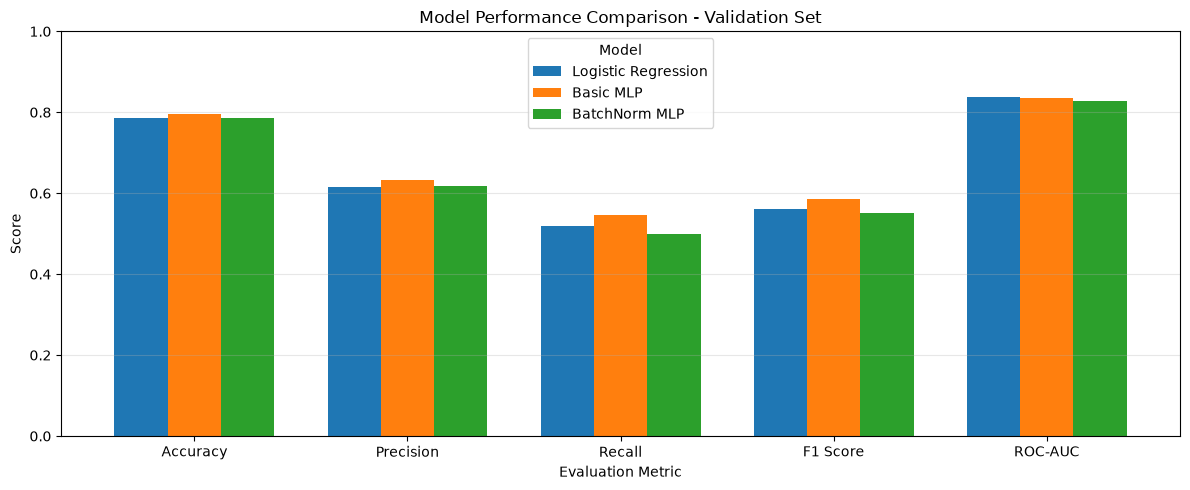

In [ ]:
#Compare all three models using validation metrics

comparison_bn = pd.concat([
    comparison,
    pd.DataFrame([{
        "Model": "BatchNorm MLP",
        "Accuracy": 0.7848,
        "Precision": 0.6167,
        "Recall": 0.5000,
        "F1 Score": 0.5523,
        "ROC-AUC": 0.8268
    }])
], ignore_index=True)

display(comparison_bn)

#Plot metrics comparison
ax = comparison_bn.set_index("Model").T.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.75
)

ax.set_title("Model Performance Comparison - Validation Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**MLP 3**: Dropout<br>
Now we will use the DropOut technique which especially designed for overfitting problems. It will randomly deactivate a proportion of neuron outputs during training. This discourages the network from relying too heavily on individual neurons.<br>
For this we will use (0.2) which randomly sets approximately 20% of the preceding layer's outputs to zero on each pass.<br>
Later when hyperparameter tuning we can investigate other rates.

In [76]:
#So build once agian the model using Dropout.

#Seed
tf.keras.utils.set_random_seed(42)

#Model
mlp_drop = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_std.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation="sigmoid")
],name="MLP_Dropout")

#Show model summary
mlp_drop.summary()

Model: "MLP_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

In [77]:
#Compile model

mlp_drop.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
             tf.keras.metrics.AUC(name="AUC")]
)

In [78]:
#Train the new model now with Dropout method.
#Again we will use same callbacks with same parameters so can compare fair results

early_stop_drop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True)

history_drop = mlp_drop.fit(
    X_train_std.to_numpy(dtype="float32"),
    y_train.to_numpy(dtype="float32"),
    validation_data = (X_val_std.to_numpy(dtype="float32"),
                       y_val.to_numpy(dtype="float32")),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop_drop],
    verbose=1
)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - AUC: 0.7434 - Accuracy: 0.7464 - loss: 0.5114 - val_AUC: 0.8189 - val_Accuracy: 0.7848 - val_loss: 0.4468
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8202 - Accuracy: 0.7858 - loss: 0.4442 - val_AUC: 0.8274 - val_Accuracy: 0.7905 - val_loss: 0.4377
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8304 - Accuracy: 0.7976 - loss: 0.4340 - val_AUC: 0.8311 - val_Accuracy: 0.7848 - val_loss: 0.4344
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8331 - Accuracy: 0.7991 - loss: 0.4322 - val_AUC: 0.8322 - val_Accuracy: 0.7858 - val_loss: 0.4331
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8379 - Accuracy: 0.7978 - loss: 0.4264 - val_AUC: 0.8319 - val_Accuracy: 0.7829 - val_loss: 0.4347
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8398 - Accuracy: 0.8011 - loss: 0.4247 - val_AUC: 0.8323 - val_Accuracy: 0.7886 - val_loss: 0.4334
Epoch 7/100
143/143 ━━━━━━━━━━━━━━

Worth to note already that dropout extented training up to epoch 9 instead of epoch 3 and 4 we had with basic and BatchNormalized model. However it still has bigger validation loss than the basic model. Beats also the BN model. That suggests that learning behaviour has changed but we cannot say yet it improved or not finally the churn detection. We need to go for validation set metrics. We will use the exact 5 same ones.<br>
First save the model and history.

In [79]:
#Save dropout model and training history
mlp_drop.save("mlp_drop.keras")

pd.DataFrame(history_drop.history).to_csv("mlp_drop_history.csv", index=False)

In [80]:
#Evaluate - validation data

#Predict probabilities
y_val_prob_drop = mlp_drop.predict(
    X_val_std.to_numpy(dtype="float32"),
    verbose=0).ravel()

#Probabilities to binary predictions
y_val_pred_drop = (y_val_prob_drop >= 0.5).astype(int)

#Metrics
print("Dropout MLP Metrics - Validation Data")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_drop), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_drop), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_drop), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_drop), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_drop), 4))
print("-" * 50)
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_drop))

Dropout MLP Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7858
Precision: 0.6144
Recall: 0.5179
F1 Score: 0.562
ROC-AUC: 0.8345
--------------------------------------------------
Confusion Matrix:
[[684  91]
 [135 145]]


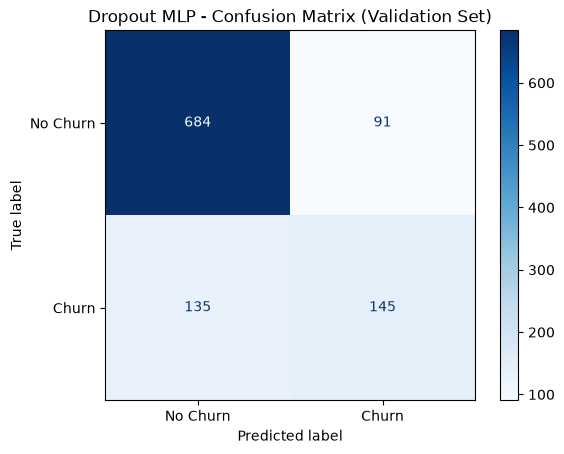

In [81]:
#Confusion Matrix (Validation Set)

cm_drop = confusion_matrix(y_val, y_val_pred_drop)

disp_drop = ConfusionMatrixDisplay(
    confusion_matrix=cm_drop,
    display_labels=["No Churn", "Churn"]
)

disp_drop.plot(cmap="Blues", values_format="d")

plt.title("Dropout MLP - Confusion Matrix (Validation Set)")
plt.show()

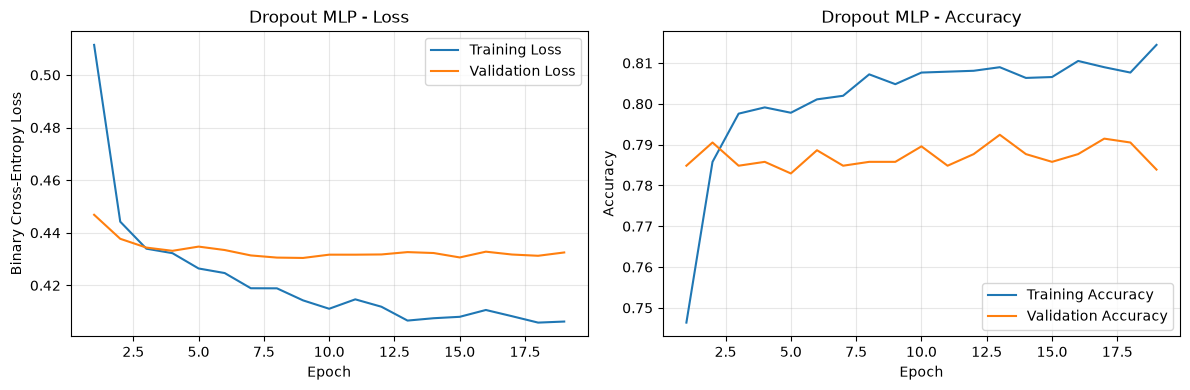

In [ ]:
#Training history plots.
#Loss and accuracy plots.

epochs_drop = range(1, len(history_drop.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Loss
axes[0].plot(epochs_drop, history_drop.history["loss"],
             label="Training Loss")
axes[0].plot(epochs_drop, history_drop.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("Dropout MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Accuracy
axes[1].plot(epochs_drop, history_drop.history["Accuracy"],
             label="Training Accuracy")
axes[1].plot(epochs_drop, history_drop.history["val_Accuracy"],
             label="Validation Accuracy")
axes[1].set_title("Dropout MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268
3,Dropout MLP,0.7858,0.6144,0.5179,0.5620,0.8345


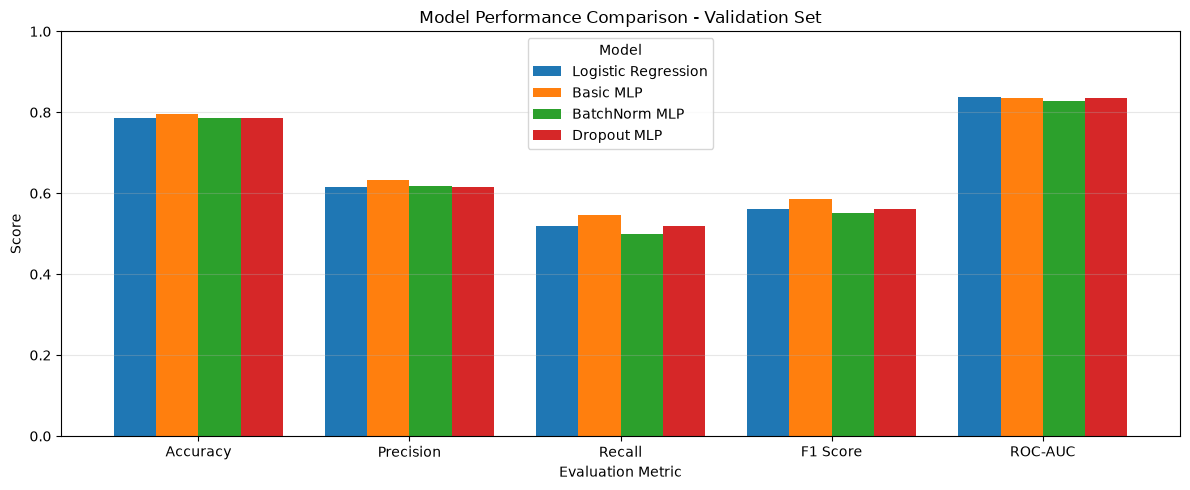

In [83]:
#Add Dropout MLP to the model comparison

comparison_drop = pd.concat([
    comparison_bn,
    pd.DataFrame([{
        "Model": "Dropout MLP",
        "Accuracy": 0.7858,
        "Precision": 0.6144,
        "Recall": 0.5179,
        "F1 Score": 0.5620,
        "ROC-AUC": 0.8345
    }])
], ignore_index=True)

display(comparison_drop)

#Compare four models visually
ax = comparison_drop.set_index("Model").T.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

ax.set_title("Model Performance Comparison - Validation Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**MLP 4**: L2 regularization.<br>
Another method for reducing overfitting.<br>
Unlike Dropout, which randomly disables neuron outputs, L2 regularization penalizes large weights, encouraging the network to learn smaller, more controlled weight values. We will use same architecture and same metrics for fair comparissons.<br>
We start with λ = 0.001 and seed 42 as always.

In [84]:
#Build again the model with L2 Regularization

#Seed
tf.keras.utils.set_random_seed(42)

#Model
mlp_l2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_std.shape[1],)),
    tf.keras.layers.Dense(32, activation="relu",
                          kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    tf.keras.layers.Dense(16, activation="relu",
                          kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    tf.keras.layers.Dense(1, activation="sigmoid")
],name="MLP_L2")

#Summary
mlp_l2.summary()

Model: "MLP_L2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 32)             │         1,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,017 (7.88 KB)

 Trainable params: 2,017 (7.88 KB)

 Non-trainable params: 0 (0.00 B)

In [85]:
#Compile L2 model

mlp_l2.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
               loss="binary_crossentropy",
               metrics=[tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
                        tf.keras.metrics.AUC(name="AUC")])

In [86]:
#Same train as always. 
early_stop_l2 = tf.keras.callbacks.EarlyStopping(monitor="val_loss",
                                                 patience=10,
                                                 restore_best_weights=True)

history_l2 = mlp_l2.fit(
    X_train_std.to_numpy(dtype="float32"),
    y_train.to_numpy(dtype="float32"),
    validation_data=(X_val_std.to_numpy(dtype="float32"),
                     y_val.to_numpy(dtype="float32")),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop_l2],
    verbose=1
)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - AUC: 0.7778 - Accuracy: 0.7659 - loss: 0.5337 - val_AUC: 0.8240 - val_Accuracy: 0.7867 - val_loss: 0.4894
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8433 - Accuracy: 0.7987 - loss: 0.4665 - val_AUC: 0.8337 - val_Accuracy: 0.7905 - val_loss: 0.4744
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8497 - Accuracy: 0.8074 - loss: 0.4543 - val_AUC: 0.8349 - val_Accuracy: 0.7934 - val_loss: 0.4692
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8521 - Accuracy: 0.8085 - loss: 0.4476 - val_AUC: 0.8346 - val_Accuracy: 0.7924 - val_loss: 0.4657
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8537 - Accuracy: 0.8094 - loss: 0.4427 - val_AUC: 0.8348 - val_Accuracy: 0.7915 - val_loss: 0.4627
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8547 - Accuracy: 0.8096 - loss: 0.4388 - val_AUC: 0.8347 - val_Accuracy: 0.7877 - val_loss: 0.4605
Epoch 7/100
143/143 ━━━━━━━━━━━━━━

In [87]:
#Save model
mlp_l2.save("mlp_l2.keras")

pd.DataFrame(history_l2.history).to_csv("mlp_l2_history.csv", index=False)

In [88]:
#Evaluation

#Predict probabilities
y_val_prob_l2 = mlp_l2.predict(
    X_val_std.to_numpy(dtype="float32"),
    verbose=0).ravel()

#Probabilities to binary predictions
y_val_pred_l2 = (y_val_prob_l2 >= 0.5).astype(int)

#Metrics
print("L2 MLP Metrics - Validation Data")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_l2), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_l2), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_l2), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_l2), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_l2), 4))
print("-" * 50)
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_l2))

L2 MLP Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7943
Precision: 0.6413
Recall: 0.5107
F1 Score: 0.5686
ROC-AUC: 0.8338
--------------------------------------------------
Confusion Matrix:
[[695  80]
 [137 143]]


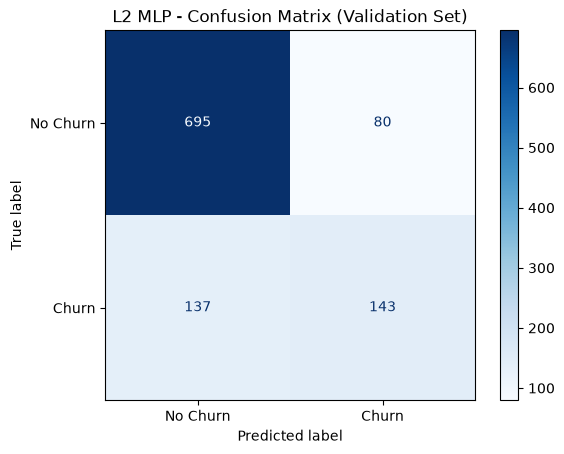

In [89]:
#Confusion Matrix (Validation Set)

cm_l2 = confusion_matrix(y_val, y_val_pred_l2)

disp_l2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_l2,
    display_labels=["No Churn", "Churn"]
)

disp_l2.plot(cmap="Blues", values_format="d")

plt.title("L2 MLP - Confusion Matrix (Validation Set)")
plt.show()

In [ ]:
#L2 makes 9 fewer false alarms but misses 10 additional churners.

#For a telecom business case, this is an important trade-off:
# - If retention campaigns are expensive, higher precision could reduce unnecessary spending.
# - If losing customers is more costly, the Basic MLP's higher recall may be preferable.

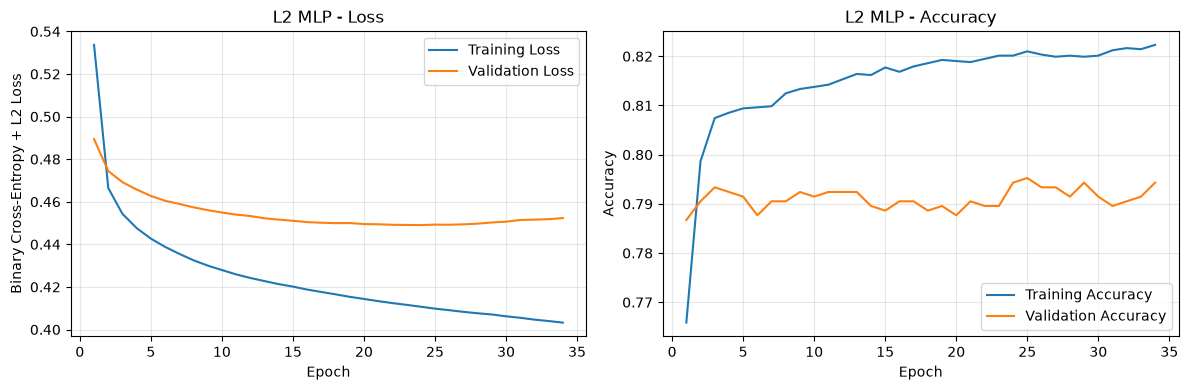

In [90]:
#History, loss and accuracy curves.

epochs_l2 = range(1, len(history_l2.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Loss
axes[0].plot(epochs_l2, history_l2.history["loss"],
             label="Training Loss")
axes[0].plot(epochs_l2, history_l2.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("L2 MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy + L2 Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Accuracy
axes[1].plot(epochs_l2, history_l2.history["Accuracy"],
             label="Training Accuracy")
axes[1].plot(epochs_l2, history_l2.history["val_Accuracy"],
             label="Validation Accuracy")
axes[1].set_title("L2 MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268
3,Dropout MLP,0.7858,0.6144,0.5179,0.5620,0.8345
4,L2 MLP,0.7943,0.6413,0.5107,0.5686,0.8338


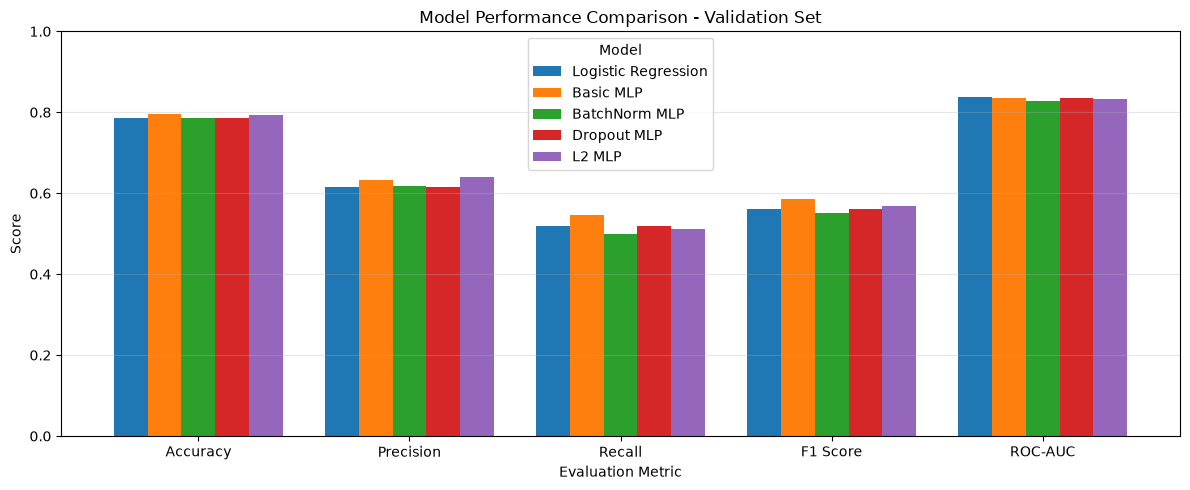

In [ ]:
#Add L2 MLP to our previous model comparison

comparison_l2 = pd.concat([
    comparison_drop,
    pd.DataFrame([{
        "Model": "L2 MLP",
        "Accuracy": 0.7943,
        "Precision": 0.6413,
        "Recall": 0.5107,
        "F1 Score": 0.5686,
        "ROC-AUC": 0.8338
    }])
], ignore_index=True)

#Display all models
display(comparison_l2)

#Plot all models
ax = comparison_l2.set_index("Model").T.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8)

ax.set_title("Model Performance Comparison - Validation Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**MLP 5**: Residual net/skip connections.<br>
Until now, information has passed sequentially through our network:<br>
**Input → Dense(32) → Dense(16) → Output**<br>
With a residual connection, we create an additional path that allows information to bypass part of the network.<br>
Expected more trainable parameters.

In [ ]:
#Build model

tf.keras.utils.set_random_seed(42)

#Input and main paths
inputs = tf.keras.Input(shape=(X_train_std.shape[1],))
x = tf.keras.layers.Dense(32, activation="relu")(inputs)
h = tf.keras.layers.Dense(16, activation="relu")(x)

#Shortcut path (match 16 features)
shortcut = tf.keras.layers.Dense(16)(x)

#Combine paths
merged = tf.keras.layers.Add()([h, shortcut])

#Output
outputs = tf.keras.layers.Dense(
    1, activation="sigmoid"
)(merged)

#Build model
mlp_res = tf.keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="MLP_Residual")

#Summary
mlp_res.summary()

Model: "MLP_Residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 45)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_25 (Dense)    │ (None, 32)        │      1,472 │ input_layer_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_26 (Dense)    │ (None, 16)        │        528 │ dense_25[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_27 (Dense)    │ (None, 16)        │        528 │ dense_25[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 16)        │          0 │ dense_26[0][0],   │
│                     │                   │            │ dense_27[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 1)         │         17 │ add[0][0]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,545 (9.94 KB)

 Trainable params: 2,545 (9.94 KB)

 Non-trainable params: 0 (0.00 B)

In [93]:
#Compile with same optimizer with other models and same metrics

mlp_res.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                loss="binary_crossentropy",
                metrics=[tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
                         tf.keras.metrics.AUC(name="AUC")])

In [94]:
#Train model with callbacks

early_stop_res = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True)

history_res = mlp_res.fit(
    X_train_std.to_numpy(dtype="float32"),
    y_train.to_numpy(dtype="float32"),
    validation_data=(
        X_val_std.to_numpy(dtype="float32"),
        y_val.to_numpy(dtype="float32")),
    batch_size=32,
    epochs=100,
    callbacks=[early_stop_res],
    verbose=1)

Epoch 1/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - AUC: 0.7912 - Accuracy: 0.7654 - loss: 0.4686 - val_AUC: 0.8252 - val_Accuracy: 0.7839 - val_loss: 0.4386
Epoch 2/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8441 - Accuracy: 0.8018 - loss: 0.4187 - val_AUC: 0.8324 - val_Accuracy: 0.7829 - val_loss: 0.4318
Epoch 3/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8501 - Accuracy: 0.8037 - loss: 0.4116 - val_AUC: 0.8326 - val_Accuracy: 0.7839 - val_loss: 0.4307
Epoch 4/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8532 - Accuracy: 0.8037 - loss: 0.4077 - val_AUC: 0.8327 - val_Accuracy: 0.7867 - val_loss: 0.4309
Epoch 5/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - AUC: 0.8553 - Accuracy: 0.8101 - loss: 0.4050 - val_AUC: 0.8320 - val_Accuracy: 0.7858 - val_loss: 0.4316
Epoch 6/100
143/143 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - AUC: 0.8570 - Accuracy: 0.8112 - loss: 0.4029 - val_AUC: 0.8315 - val_Accuracy: 0.7848 - val_loss: 0.4316
Epoch 7/100
143/143 ━━━━━━━━━━━━━━

In [95]:
#Save model and training history

mlp_res.save("mlp_res.keras")

pd.DataFrame(history_res.history).to_csv("mlp_res_history.csv",index=False)

In [96]:
#Evaluate (validation data)

#Predict
y_val_prob_res = mlp_res.predict(
    X_val_std.to_numpy(dtype="float32"),
    verbose=0).ravel()

#Probabilities to binary predictions
y_val_pred_res = (y_val_prob_res >= 0.5).astype(int)

#Metrics
print("Residual MLP Metrics - Validation Data")
print("-" * 50)
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_res), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_res), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_res), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_res), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_prob_res), 4))
print("-" * 50)
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_res))

Residual MLP Metrics - Validation Data
--------------------------------------------------
Accuracy: 0.7839
Precision: 0.6066
Recall: 0.5286
F1 Score: 0.5649
ROC-AUC: 0.8326
--------------------------------------------------
Confusion Matrix:
[[679  96]
 [132 148]]


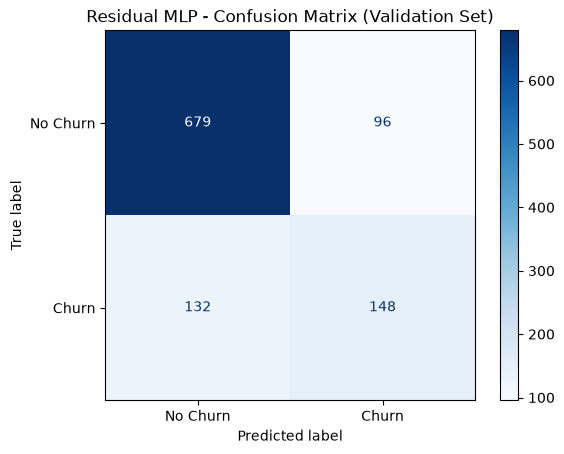

In [97]:
#Confusion Matrix (Validation Set)

cm_res = confusion_matrix(y_val, y_val_pred_res)

disp_res = ConfusionMatrixDisplay(
    confusion_matrix=cm_res,
    display_labels=["No Churn", "Churn"])

disp_res.plot(cmap="Blues", values_format="d")

plt.title("Residual MLP - Confusion Matrix (Validation Set)")
plt.show()

Complexity doesn't necessarily improve performance, particularly on a relatively small dataset.

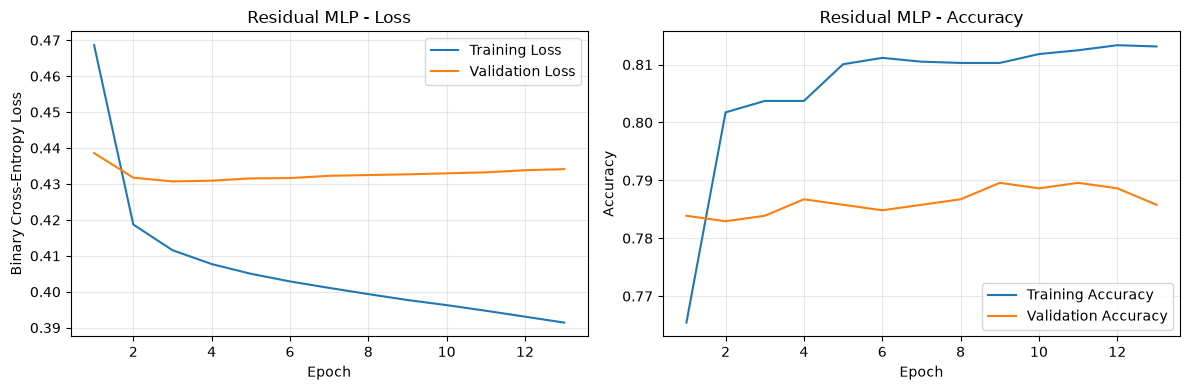

In [98]:
#Training History

epochs_res = range(1, len(history_res.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#Loss
axes[0].plot(epochs_res, history_res.history["loss"],
             label="Training Loss")
axes[0].plot(epochs_res, history_res.history["val_loss"],
             label="Validation Loss")
axes[0].set_title("Residual MLP - Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

#Accuracy
axes[1].plot(epochs_res, history_res.history["Accuracy"],
             label="Training Accuracy")
axes[1].plot(epochs_res, history_res.history["val_Accuracy"],
             label="Validation Accuracy")
axes[1].set_title("Residual MLP - Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268
3,Dropout MLP,0.7858,0.6144,0.5179,0.5620,0.8345
4,L2 MLP,0.7943,0.6413,0.5107,0.5686,0.8338
5,Residual MLP,0.7839,0.6066,0.5286,0.5649,0.8326


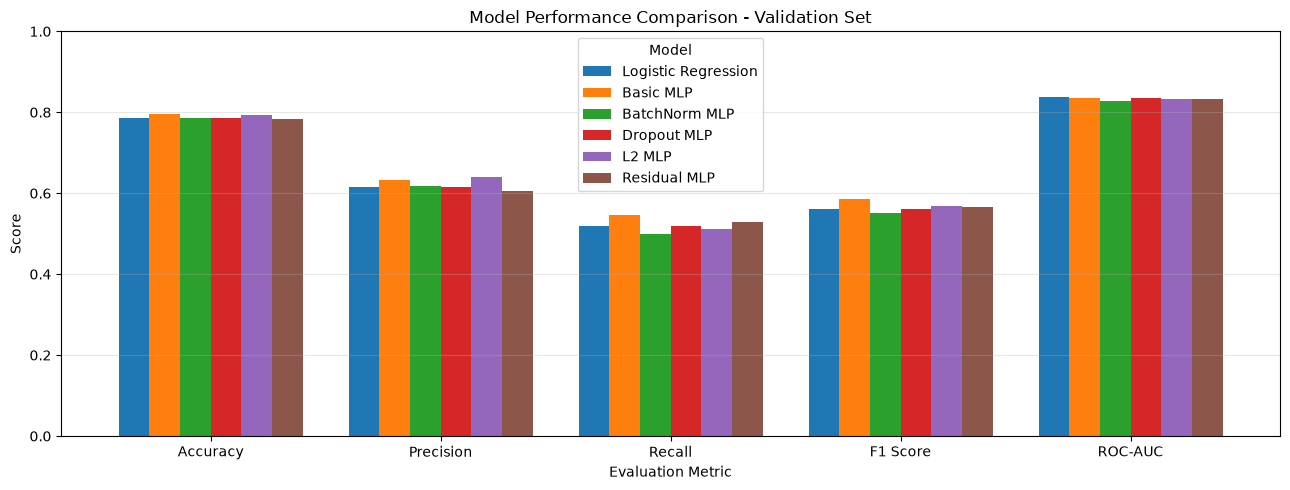

In [ ]:
#Add Residual MLP

comparison_res = pd.concat([
    comparison_l2,
    pd.DataFrame([{
        "Model": "Residual MLP",
        "Accuracy": 0.7839,
        "Precision": 0.6066,
        "Recall": 0.5286,
        "F1 Score": 0.5649,
        "ROC-AUC": 0.8326
    }])
], ignore_index=True)

#Display table
display(comparison_res)

#Plot all six models
ax = comparison_res.set_index("Model").T.plot(
    kind="bar",
    figsize=(13, 5),
    width=0.8)

ax.set_title("Model Performance Comparison - Validation Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
#Quick check datasets

print("Training:", X_train_std.shape)
print("Validation:", X_val_std.shape)
print("Testing:", X_test_std.shape)

print("Missing training values:", X_train_std.isna().sum().sum())
print("Missing validation values:", X_val_std.isna().sum().sum())

Training: (4570, 45)
Validation: (1055, 45)
Testing: (1407, 45)
Missing training values: 0
Missing validation values: 0


**Hyperparameters Tuning**: KerasTuner

In [30]:
import keras_tuner as kt

print("KerasTuner version:", kt.__version__)

KerasTuner version: 1.4.8


In [42]:
#Architecture

def build_tuned_mlp(hp):

    units_1 = hp.Choice("units_1", [16, 32, 64])
    units_2 = hp.Choice("units_2", [8, 16, 32])
    dropout_rate = hp.Choice("dropout_rate", [0.0, 0.2])
    l2_strength = hp.Choice("l2_strength", [0.0, 0.0001, 0.001])
    learning_rate = hp.Choice("learning_rate", [0.0003, 0.001])

    regularizer = (
        tf.keras.regularizers.l2(l2_strength)
        if l2_strength > 0 else None)

    model = tf.keras.Sequential([
        tf.keras.Input(shape=(X_train_std.shape[1],)),

        tf.keras.layers.Dense(
            units_1,
            activation="relu",
            kernel_regularizer=regularizer),

        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(
            units_2,
            activation="relu",
            kernel_regularizer=regularizer),

        tf.keras.layers.Dropout(dropout_rate),

        tf.keras.layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="Accuracy"),
            tf.keras.metrics.AUC(name="AUC")]
    )

    return model

print("Done")

Done


In [ ]:
#Configure

tuner = kt.RandomSearch(
    hypermodel=build_tuned_mlp,
    objective=kt.Objective("val_AUC", direction="max"),
    max_trials=12,
    seed=42,
    directory="keras_tuner_results",
    project_name="telco_mlp_auc_v2",
    overwrite=False)

tuner.search_space_summary()

Search space summary
Default search space size: 5
units_1 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64], 'ordered': True}
units_2 (Choice)
{'default': 8, 'conditions': [], 'values': [8, 16, 32], 'ordered': True}
dropout_rate (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.2], 'ordered': True}
l2_strength (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001], 'ordered': True}
learning_rate (Choice)
{'default': 0.0003, 'conditions': [], 'values': [0.0003, 0.001], 'ordered': True}


In [44]:
#CallBacks

early_stop_tune = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True)

print("Early Stopping done.")

Early Stopping done.


In [49]:
#Run hyperparameter search

tuner.search(
    X_train_std.astype("float32"),
    y_train.astype("float32"),

    validation_data=(
        X_val_std.astype("float32"),
        y_val.astype("float32")),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop_tune],
    verbose=1)

print("Ok.")

Trial 12 Complete [00h 00m 33s]
val_AUC: 0.8361083269119263

Best val_AUC So Far: 0.8381105661392212
Total elapsed time: 00h 07m 33s
Ok.


In [31]:
#Forgot the tensorboard

import tensorboard

In [48]:
#Reset tuner and make fresh start

tuner = kt.RandomSearch(
    hypermodel=build_tuned_mlp,
    objective=kt.Objective("val_AUC", direction="max"),
    max_trials=12,
    seed=42,
    directory="keras_tuner_results",
    project_name="telco_mlp_auc_v2",
    overwrite=False)

In [50]:
#Best hyperparameters

best_hp = tuner.get_best_hyperparameters(1)[0]

for name, value in best_hp.values.items():
    print(name, ":", value)

print("Best validation AUC:", tuner.oracle.get_best_trials(1)[0].score)

units_1 : 64
units_2 : 16
dropout_rate : 0.0
l2_strength : 0.0001
learning_rate : 0.0003
Best validation AUC: 0.8381105661392212


In [51]:
#Save best model

mlp_tuned = tuner.get_best_models(num_models=1)[0]
mlp_tuned.save("mlp_tuned.keras")

print("Saved.")

Saved.


c:\Users\Owner\Desktop\Essex\03_Main\Data\DeepLearning\vs\.venv\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(store)


In [52]:
#Evaluate the tuned MLP - Validation Data

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix)

y_val_proba_tuned = mlp_tuned.predict(
    X_val_std.astype("float32"),
    verbose=0).ravel()

y_val_pred_tuned = (y_val_proba_tuned >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_val, y_val_pred_tuned), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_tuned), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_tuned), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba_tuned), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

Accuracy: 0.7829
Precision: 0.6016
Recall: 0.5393
F1 Score: 0.5687
ROC-AUC: 0.838

Confusion Matrix:
[[675 100]
 [129 151]]


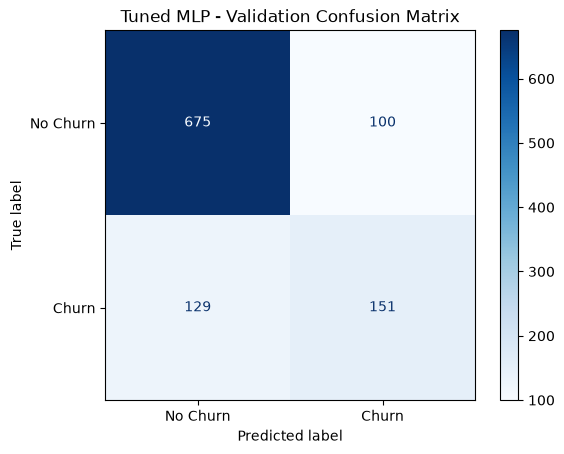

In [53]:
#Confusion matrix

from sklearn.metrics import ConfusionMatrixDisplay

cm_tuned = confusion_matrix(y_val, y_val_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["No Churn", "Churn"])

disp.plot(cmap="Blues")
plt.title("Tuned MLP - Validation Confusion Matrix")
plt.show()

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268
3,Dropout MLP,0.7858,0.6144,0.5179,0.5620,0.8345
4,L2 MLP,0.7943,0.6413,0.5107,0.5686,0.8338
5,Residual MLP,0.7839,0.6066,0.5286,0.5649,0.8326
6,Tuned MLP,0.7829,0.6016,0.5393,0.5687,0.8380


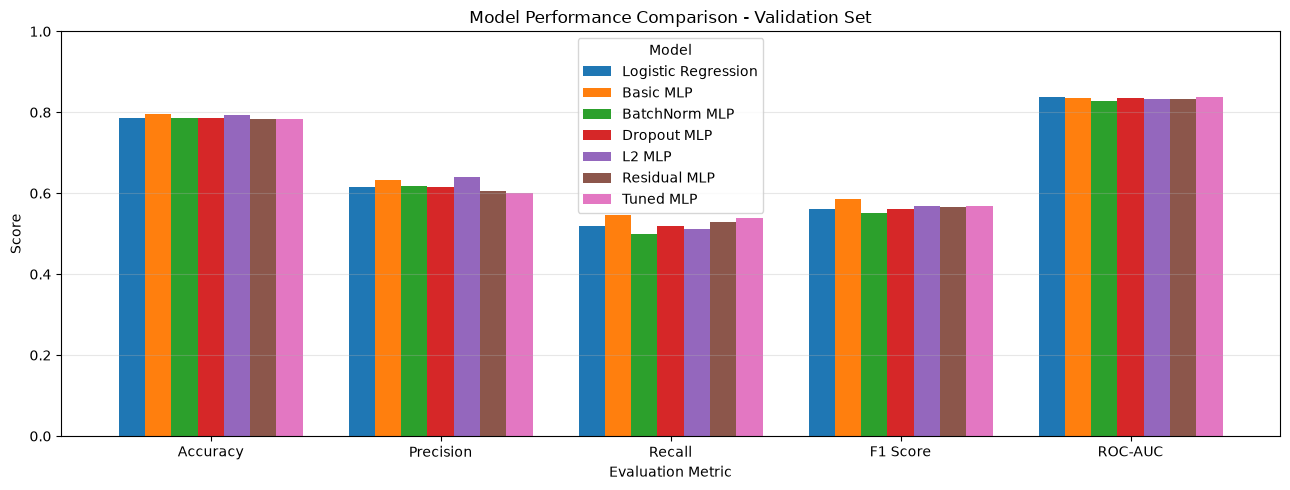

In [54]:
#All seven models on validation data

comparison_7 = pd.DataFrame([
    ["Logistic Regression", 0.7858, 0.6144, 0.5179, 0.5620, 0.8369],
    ["Basic MLP",           0.7953, 0.6322, 0.5464, 0.5862, 0.8343],
    ["BatchNorm MLP",       0.7848, 0.6167, 0.5000, 0.5523, 0.8268],
    ["Dropout MLP",         0.7858, 0.6144, 0.5179, 0.5620, 0.8345],
    ["L2 MLP",              0.7943, 0.6413, 0.5107, 0.5686, 0.8338],
    ["Residual MLP",        0.7839, 0.6066, 0.5286, 0.5649, 0.8326],
    ["Tuned MLP",           0.7829, 0.6016, 0.5393, 0.5687, 0.8380]
], columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"
])

display(comparison_7)

ax = comparison_7.set_index("Model").T.plot(
    kind="bar",
    figsize=(13, 5),
    width=0.8
)

ax.set_title("Model Performance Comparison - Validation Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [55]:
#Save models comparison
comparison_7.to_csv("comparison_7_validation.csv", index=False)

#Save tuning trials and parameters
trials_data = []

for trial in tuner.oracle.trials.values():
    trials_data.append({
        "Trial": trial.trial_id,
        "Status": trial.status,
        "val_AUC": trial.score,
        **trial.hyperparameters.values
    })

trials_df = pd.DataFrame(trials_data)
trials_df = trials_df.sort_values("val_AUC", ascending=False)

trials_df.to_csv("tuning_trials.csv", index=False)

display(trials_df)

,Trial,Status,val_AUC,units_1,units_2,dropout_rate,l2_strength,learning_rate
4,04,COMPLETED,0.838111,64,16,0.0,0.0001,0.0003
9,09,COMPLETED,0.837977,32,32,0.2,0.0010,0.0003
0,00,COMPLETED,0.837615,32,8,0.0,0.0000,0.0010
5,05,COMPLETED,0.837106,16,32,0.2,0.0010,0.0003
11,11,COMPLETED,0.836108,16,32,0.2,0.0010,0.0010
7,07,COMPLETED,0.836037,64,32,0.0,0.0000,0.0010
8,08,COMPLETED,0.835880,16,16,0.2,0.0000,0.0010
2,02,COMPLETED,0.835687,64,16,0.2,0.0000,0.0010
6,06,COMPLETED,0.835479,16,8,0.2,0.0001,0.0003
3,03,COMPLETED,0.833726,16,16,0.0,0.0000,0.0003


In [32]:
print("Training:", X_train_std.shape)
print("Validation:", X_val_std.shape)
print("Testing:", X_test_std.shape)

print("Missing training values:", X_train_std.isna().sum().sum())
print("Missing validation values:", X_val_std.isna().sum().sum())

Training: (4570, 45)
Validation: (1055, 45)
Testing: (1407, 45)
Missing training values: 0
Missing validation values: 0


For feature importance **SHAP** method is picked. In simple words "Across many customers, which features have the greatest average influence on our network's predictions?", this is the question we trying to answer. This for sure explains model behaviour and not real world causes of customer churn.<br>
For this method we going to load the basic MLP. This is because it achieved the best Recall and F1-score among all seven models at threshold 0.5.

In [35]:
#Load basic MLP model, set seed 42

tf.keras.utils.set_random_seed(42)

mlp_shap = tf.keras.models.load_model("mlp_basic.keras",
                                      compile=False)

#Check
print("Model loaded:", mlp_shap.name)
print("Ipnut Shape:", mlp_shap.input_shape)

Model loaded: MLP_Basic
Ipnut Shape: (None, 45)


In [ ]:
#SHAP library

import shap

print("SHAP version:", shap.__version__)

c:\Users\Owner\Desktop\Essex\03_Main\Data\DeepLearning\vs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP version: 0.54.1


In [39]:
#Reproducable sample from train and validation data.
#50 training clients and 30 validation clients, with seed=42 in case we need to repeat

X_background = X_train_std.sample(n=50,random_state=42)

X_explain = X_val_std.sample(n=30,random_state=42)

print("Background:", X_background.shape)
print("Explain:", X_explain.shape)

Background: (50, 45)
Explain: (30, 45)


In [43]:
#Create SHAP

def predict_churn(data):
    data = np.asarray(data, dtype=np.float32)
    return mlp_shap.predict(data, verbose=0).ravel()

explainer = shap.KernelExplainer(
    predict_churn,
    X_background,
    link="identity")

print("Ok.")

Ok.


In [42]:
#I thought i did. Anyway numpy loaded again so we can retry above cell.
import numpy as np

In [44]:
#SHAP values, set seed = 42

np.random.seed(42)

shap_values = explainer.shap_values(
    X_explain,
    nsamples=200)

#Save output
np.save("shap_basic_values.npy", shap_values)

print("SHAP shape:", np.asarray(shap_values).shape)
print("Ok.")

100%|██████████| 30/30 [00:23<00:00,  1.26it/s]

SHAP shape: (30, 45)
Ok.


**Conclude**:<br>
1. SHAP calculated contributions for all 30 clients picked.<br>
2. It covered all 45 processed features.<br>
3. All results saved at shap_vasic_values

C:\Users\Owner\AppData\Local\Temp\ipykernel_220376\724098606.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


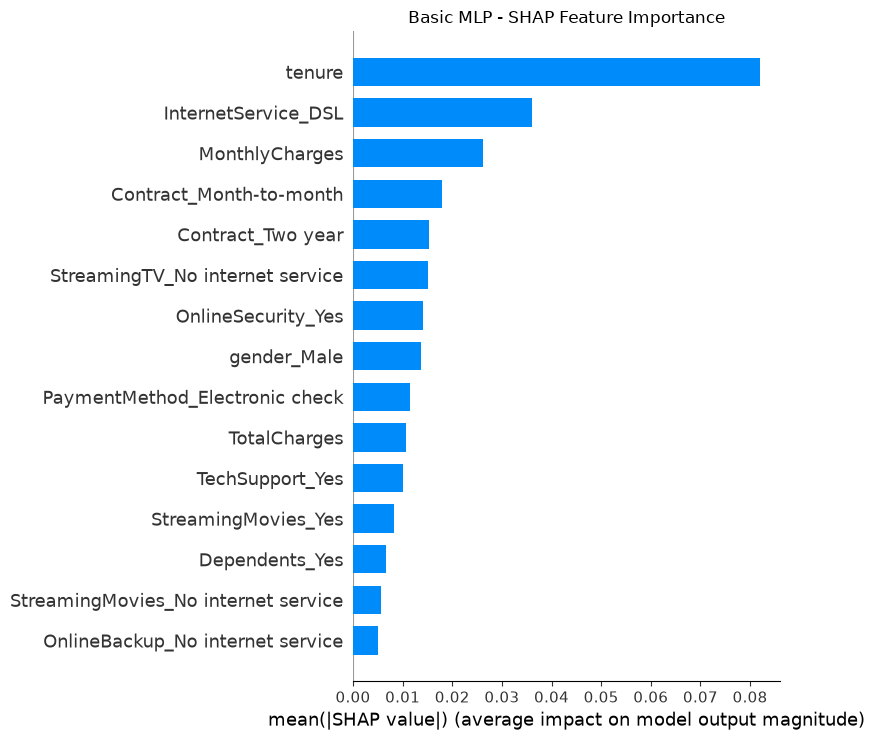

In [45]:
#Feature importance for Basic MLP network

import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values,
    X_explain,
    plot_type="bar",
    max_display=15,
    show=False)

plt.title("Basic MLP - SHAP Feature Importance")
plt.tight_layout()
plt.savefig("shap_basic_importance.png", dpi=200, bbox_inches="tight")
plt.show()

C:\Users\Owner\AppData\Local\Temp\ipykernel_220376\1224879868.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


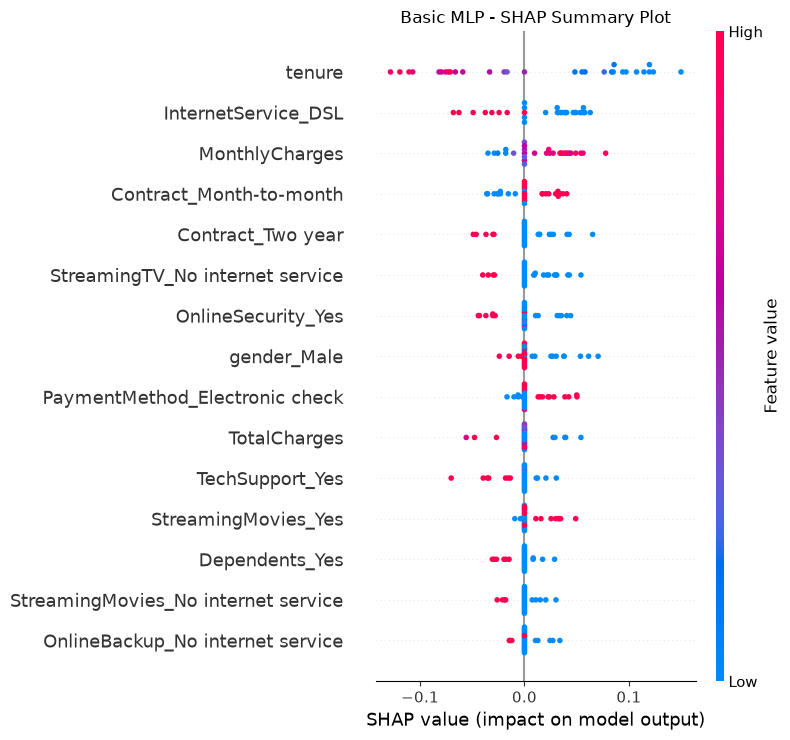

In [46]:
#SHAP summary plot - Basic MLP

shap.summary_plot(
    shap_values,
    X_explain,
    max_display=15,
    show=False)

plt.title("Basic MLP - SHAP Summary Plot")
plt.tight_layout()
plt.savefig("shap_basic_summary.png", dpi=200, bbox_inches="tight")
plt.show()

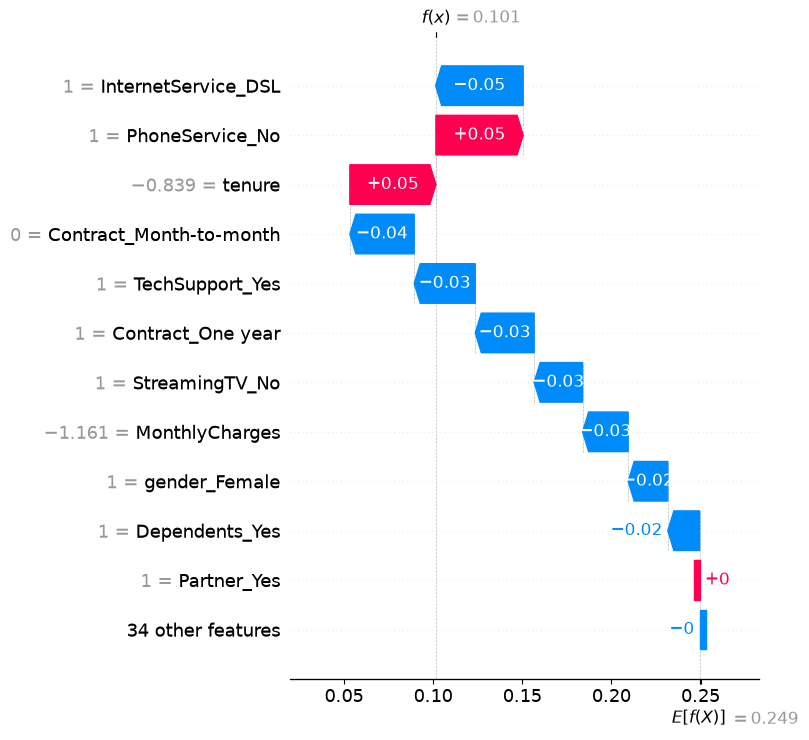

In [47]:
#Explanation for one customer

customer_shap = shap.Explanation(
    values=shap_values[0],
    base_values=float(np.asarray(explainer.expected_value).squeeze()),
    data=X_explain.iloc[0].values,
    feature_names=X_explain.columns.tolist())

shap.plots.waterfall(
    customer_shap,
    max_display=12,
    show=False)

plt.tight_layout()
plt.savefig("shap_basic_customer.png", dpi=200, bbox_inches="tight")
plt.show()

How it droped from almost 25% to final, a bit over 10%

DSL internet: Decreases the prediction by approximately 5 percentage points.
No phone service: Increases it by approximately 5 percentage points.
Tenure: Increases it by approximately 5 percentage points. The standardized value of −0.839 indicates relatively short tenure.
Not having a month-to-month contract: Decreases the prediction by approximately 4 percentage points.
Having technical support: Decreases it by approximately 3 percentage points.

In [48]:
print("Data:", X_train_std.shape)
print("Model:", mlp_shap.name)
print("SHAP:", np.asarray(shap_values).shape)

Data: (4570, 45)
Model: MLP_Basic
SHAP: (30, 45)


In [49]:
#Save SHAP samples and reference values if needed for later analysis

X_background.to_csv("shap_background.csv", index=False)
X_explain.to_csv("shap_customers.csv", index=False)

np.save("shap_reference.npy", np.asarray(explainer.expected_value))

print("Saved.")

Saved.


### **PART 4** - More Models

We will try evaluate two more models on the same validation dataset and train them with the same training set we used for all previous models. So finally we can have a comparison of simple/basic MLP to more advanced or even tuned and then with other models like Random Forest and XGBoost.

**Random Forest**<br>
We'll train it on the same 4,570 training customers, using the same 45 features.<br>
200 trees chosen with a minimum of 3 training samples per leaf to limit overly specific splits.

In [50]:
#Random Forest

from sklearn.ensemble import RandomForestClassifier
import joblib

rf_model = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1)

#Fit
rf_model.fit(X_train_std, y_train)

#Save
joblib.dump(rf_model, "random_forest.joblib")

#Print
print("Ok.")

Ok.


In [51]:
#Predict, evaluate the model on validation set

#Import metric tools
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix)

#Predict
y_val_pred_rf = rf_model.predict(X_val_std)
y_val_proba_rf = rf_model.predict_proba(X_val_std)[:, 1]

#Print Metrics
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_rf), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_rf), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_rf), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

Accuracy: 0.7839
Precision: 0.6238
Recall: 0.4679
F1 Score: 0.5347
ROC-AUC: 0.8266

Confusion Matrix:
[[696  79]
 [149 131]]


**XGBOOST**

Training Parameters:<br>
1. 200 trees: The model builds trees sequentially, correcting previous errors.<br>
2. Maximum depth 3: Keeps individual trees relatively simple.<br>
3. Learning rate 0.05: Controls how strongly each new tree contributes.<br>
4. Subsample 0.8: Each tree uses a random subset of training customers.<br>
5. Seed 42: Reproducibility.

In [55]:
#Checking if it needs install

import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [54]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 699.0 kB/s eta 0:01:10
   ---------------------------------------- 0.5/48.9 MB 699.0 kB/s eta 0:01:10
    --------------------------------------- 0.8/48.9 MB 657.8 kB/s eta 0:01:14
    --------------------------------------- 0.8/48.9 MB 657.8 kB/s eta 0:01:14
    --------------------------------------- 1.0/48.9 MB 662.0 kB/s eta 0:01:13
    --------------------------------------- 1.0/48.9 MB 662.0 kB/s eta 0:01:13
   - -------------------------------------- 1.3/48.9 MB 664.1 kB/s eta 0:01:12
   - -------------------------------------- 1.8/48.9 MB 824.8 kB/s eta 0:00:58
   - -------------------------------------- 2.4/48.9 MB 1.0 MB/s eta 0:00:47
   - ------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
#Build XGBoost model

#Import
from xgboost import XGBClassifier
import joblib

#Model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1)

#Fit
xgb_model.fit(X_train_std, y_train)

#Save
joblib.dump(xgb_model, "xgboost_model.joblib")

#Print when done
print("Done.")

Done.


In [58]:
#Evaluate on validation data

#Predict
y_val_pred_xgb = xgb_model.predict(X_val_std)
y_val_proba_xgb = xgb_model.predict_proba(X_val_std)[:, 1]

#Print Metrics
print("Accuracy:", round(accuracy_score(y_val, y_val_pred_xgb), 4))
print("Precision:", round(precision_score(y_val, y_val_pred_xgb), 4))
print("Recall:", round(recall_score(y_val, y_val_pred_xgb), 4))
print("F1 Score:", round(f1_score(y_val, y_val_pred_xgb), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_val_proba_xgb), 4))

#Print Confussion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_xgb))

Accuracy: 0.7991
Precision: 0.6667
Recall: 0.4857
F1 Score: 0.562
ROC-AUC: 0.8362

Confusion Matrix:
[[707  68]
 [144 136]]


We can now compare all 9 models at validation dataset.

In [59]:
#Libraries

import pandas as pd
import matplotlib.pyplot as plt

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7858,0.6144,0.5179,0.5620,0.8369
1,Basic MLP,0.7953,0.6322,0.5464,0.5862,0.8343
2,BatchNorm MLP,0.7848,0.6167,0.5000,0.5523,0.8268
3,Dropout MLP,0.7858,0.6144,0.5179,0.5620,0.8345
4,L2 MLP,0.7943,0.6413,0.5107,0.5686,0.8338
5,Residual MLP,0.7839,0.6066,0.5286,0.5649,0.8326
6,Tuned MLP,0.7829,0.6016,0.5393,0.5687,0.8380
7,Random Forest,0.7839,0.6238,0.4679,0.5347,0.8266
8,XGBoost,0.7991,0.6667,0.4857,0.5620,0.8362


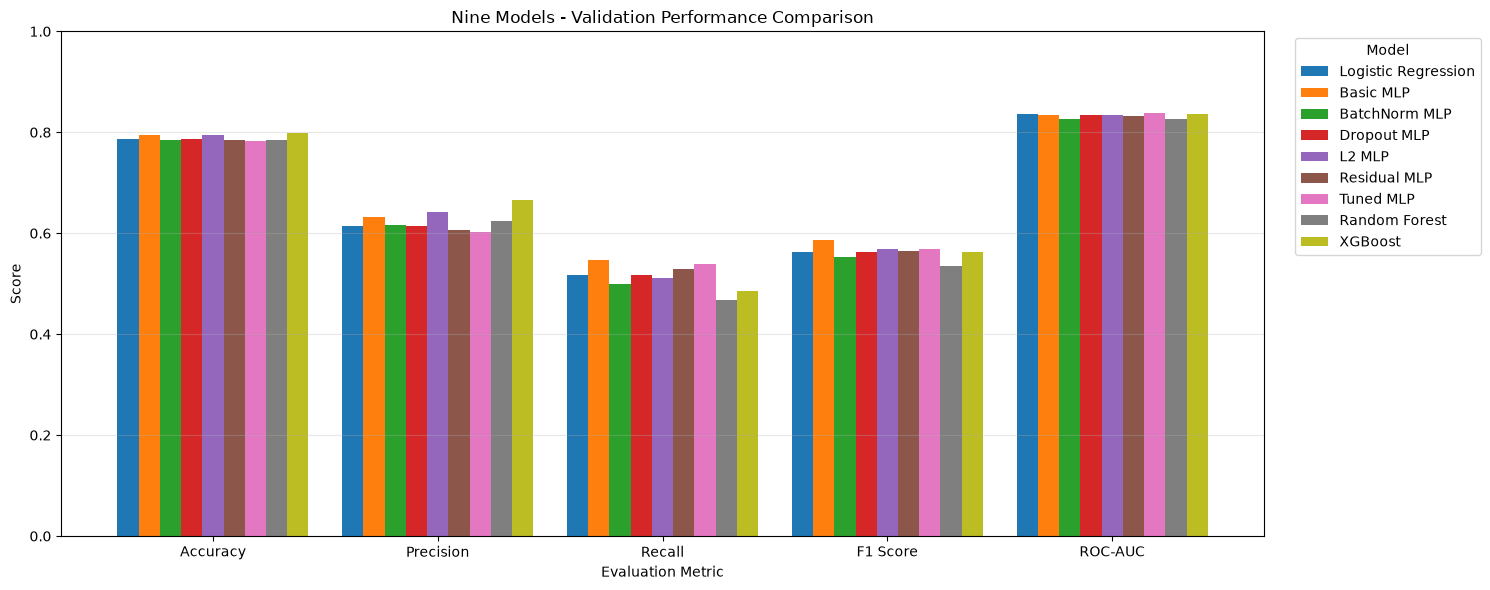

In [60]:
#Load previous 7 models
comparison_9 = pd.read_csv("comparison_7_validation.csv")

#Add the two new models
new_models = pd.DataFrame([
    ["Random Forest", 0.7839, 0.6238, 0.4679, 0.5347, 0.8266],
    ["XGBoost", 0.7991, 0.6667, 0.4857, 0.5620, 0.8362]
], columns=comparison_9.columns)

comparison_9 = pd.concat(
    [comparison_9, new_models],
    ignore_index=True)

#Display
display(comparison_9)

#Plot
ax = comparison_9.set_index("Model").T.plot(
    kind="bar",
    figsize=(15, 6),
    width=0.85)

ax.set_title("Nine Models - Validation Performance Comparison")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparison_9_validation.png", dpi=200, bbox_inches="tight")
plt.show()

#Save
comparison_9.to_csv("comparison_9_validation.csv", index=False)

### **PART 4** - Test Set - Buisness Analysis

We cant test all models on the test set we have from start (since data clean + split). Models we will use on test set for the final comparison are:<br>
1. Logistic Regression. Our original baseline. Must be there.<br>
2. Basic MLP. Was the one with highest Recall and F1-score.<br>
3. Tuned MLP. Highest ROC-AUC.<br>
4. XGBoost. Highest Accuracy and Precision. And also performed better from thd two additional ML models.<br>

In [61]:
#Load the four selected models

#Library
import joblib

#Logistic
lr_final = joblib.load("logistic_regression.joblib")

#Basic MLP
basic_final = tf.keras.models.load_model(
    "mlp_basic.keras", compile=False)

#Tuned MLP
tuned_final = tf.keras.models.load_model(
    "mlp_tuned.keras", compile=False)

#XGBoost
xgb_final = joblib.load("xgboost_model.joblib")

#Confirm loading.
print("All four models loaded.")

All four models loaded.


**Final Evaluation**<br>
For this finally the test set that is not shown anywhere up to now is time to come in front.<br>
Same metrics and also threshold at 0.5 for sigmoid like we did at train and validation stage. We keep same process.<br>
At this stage, **no training, no changes to weights, no parameter adjustments.** Only the final test results of each model.

In [62]:
#Final evaluation on the test set

from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix)

test_probabilities = {
    "Logistic Regression": lr_final.predict_proba(X_test_std)[:, 1],
    "Basic MLP": basic_final.predict(
        X_test_std.astype("float32"), verbose=0
    ).ravel(),
    "Tuned MLP": tuned_final.predict(
        X_test_std.astype("float32"), verbose=0
    ).ravel(),
    "XGBoost": xgb_final.predict_proba(X_test_std)[:, 1]
}

test_results = []
test_matrices = {}

for name, proba in test_probabilities.items():
    pred = (proba >= 0.5).astype(int)

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1 Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

    test_matrices[name] = confusion_matrix(y_test, pred)

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))

for name, cm in test_matrices.items():
    print("\n", name)
    print(cm)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7974,0.6313,0.5722,0.6003,0.8352
1,Basic MLP,0.7974,0.6282,0.5829,0.6047,0.8300
2,Tuned MLP,0.7974,0.6246,0.5963,0.6101,0.8356
3,XGBoost,0.7932,0.6334,0.5267,0.5752,0.8381



 Logistic Regression
[[908 125]
 [160 214]]

 Basic MLP
[[904 129]
 [156 218]]

 Tuned MLP
[[899 134]
 [151 223]]

 XGBoost
[[919 114]
 [177 197]]


In [ ]:
#Show and save final test set results.

display(test_comparison.round(4))

test_comparison.to_csv(
    "comparison_final_test.csv",
    index=False)

print("Saved.")

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7974,0.6313,0.5722,0.6003,0.8352
1,Basic MLP,0.7974,0.6282,0.5829,0.6047,0.8300
2,Tuned MLP,0.7974,0.6246,0.5963,0.6101,0.8356
3,XGBoost,0.7932,0.6334,0.5267,0.5752,0.8381


Saved.


Important findings
1. Tuned MLP - Best at detecting churners. It correctly identified 223 of the 374 churners, achieving Recall 59.63% and F1-score 0.6101.
2. XGBoost - Best ROC-AUC. It achieved 0.8381, indicating slightly stronger overall discrimination on the test set. However, it missed 177 churners at the 0.5 threshold.
3. Logistic Regression remains competitive. Despite being considerably simpler than our neural networks, it achieved ROC-AUC 0.8352.
4. Model selection depends on business priorities. The differences are small, so we shouldn't claim that any one model is universally superior. These are the observed results from our particular test sample.

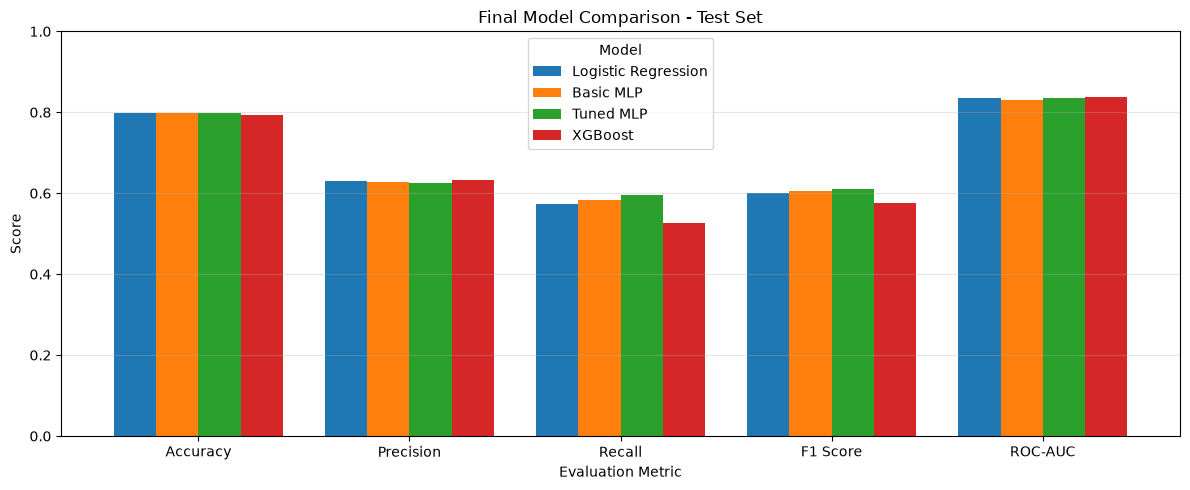

In [64]:
#Test set performance of the models

import matplotlib.pyplot as plt

ax = test_comparison.set_index("Model").T.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8)

ax.set_title("Final Model Comparison - Test Set")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("comparison_final_test.png", dpi=200, bbox_inches="tight")
plt.show()